
# Tourism Emotional Drift: Visualization and Comparative Analysis

## Objective

This notebook presents the final visual and comparative analysis of emotional drift in TripAdvisor reviews from 10 tourist destinations between 2019 and 2024.

The analysis uses outputs from the emotion classification, emotional drift detection, robustness analysis, and event mapping notebooks.

The main objectives are:
- Compare emotional patterns across destinations.
- Visualize monthly drift and important transitions.
- Examine sample-size and attraction-composition effects.
- Summarize event-mapping findings.
- Generate publication-quality figures for the MSc thesis.


In [1]:

# STEP 1: IMPORT LIBRARIES AND SET PATHS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Use the project folder as the working directory
project_dir = Path.cwd()

results_dir = project_dir / "results"
figures_dir = project_dir / "figures" / "final_thesis"

figures_dir.mkdir(parents=True, exist_ok=True)

# Existing analysis files
monthly_file = results_dir / "Monthly_Emotion_Profiles.csv"
drift_file = results_dir / "Emotional_Drift_Results.csv"
candidates_file = results_dir / "Event_Mapping_Candidates.csv"

# Check the files
for file in [monthly_file, drift_file, candidates_file]:
    print(file.name, ":", "Found" if file.exists() else "Missing")


Monthly_Emotion_Profiles.csv : Found
Emotional_Drift_Results.csv : Found
Event_Mapping_Candidates.csv : Found


In [2]:

# STEP 2: LOAD AND INSPECT DATASETS

monthly_df = pd.read_csv(monthly_file)
drift_df = pd.read_csv(drift_file)
candidates_df = pd.read_csv(candidates_file)

print("MONTHLY EMOTION PROFILES")
print("Shape:", monthly_df.shape)
print("Columns:", monthly_df.columns.tolist())

print("\nEMOTIONAL DRIFT RESULTS")
print("Shape:", drift_df.shape)
print("Columns:", drift_df.columns.tolist())

print("\nEVENT MAPPING CANDIDATES")
print("Shape:", candidates_df.shape)
print("Columns:", candidates_df.columns.tolist())

print("\nCities in the drift dataset:")
print(sorted(drift_df["City"].dropna().unique()))

display(drift_df.head())


MONTHLY EMOTION PROFILES
Shape: (675, 11)
Columns: ['City', 'Month_Year', 'Review_Count', 'Anger', 'Disgust', 'Fear', 'Joy', 'Neutral', 'Sadness', 'Surprise', 'Emotion_Total']

EMOTIONAL DRIFT RESULTS
Shape: (479, 36)
Columns: ['City', 'Month_Year', 'Review_Count', 'Anger', 'Disgust', 'Fear', 'Joy', 'Neutral', 'Sadness', 'Surprise', 'Emotion_Total', 'Previous_Month', 'Month_Gap', 'Previous_Anger', 'Previous_Disgust', 'Previous_Fear', 'Previous_Joy', 'Previous_Neutral', 'Previous_Sadness', 'Previous_Surprise', 'Previous_Review_Count', 'JS_Drift', 'Cosine_Drift', 'City_Median_JS', 'City_MAD_JS', 'Robust_Z', 'Is_Spike', 'Delta_Anger', 'Delta_Disgust', 'Delta_Fear', 'Delta_Joy', 'Delta_Neutral', 'Delta_Sadness', 'Delta_Surprise', 'Dominant_Emotion', 'Dominant_Change']

EVENT MAPPING CANDIDATES
Shape: (12, 19)
Columns: ['City', 'Previous_Month', 'Month_Year', 'Previous_Review_Count', 'Review_Count', 'JS_Drift', 'Cosine_Drift', 'Robust_Z', 'Drift_Category', 'Dominant_Emotion', 'Dominant_Chan

,City,Month_Year,Review_Count,Anger,Disgust,Fear,Joy,Neutral,Sadness,Surprise,...,Is_Spike,Delta_Anger,Delta_Disgust,Delta_Fear,Delta_Joy,Delta_Neutral,Delta_Sadness,Delta_Surprise,Dominant_Emotion,Dominant_Change
0,Agra,2019-02-01,146,0.041761,0.043144,0.035883,0.304585,0.300946,0.059196,0.214485,...,False,0.033125,0.027912,0.008348,0.014007,-0.070824,-0.072432,0.059863,Sadness,-0.072432
1,Agra,2019-03-01,67,0.032286,0.057432,0.035815,0.361505,0.293344,0.078165,0.141452,...,False,-0.009475,0.014289,-0.000068,0.056921,-0.007602,0.018969,-0.073033,Surprise,-0.073033
2,Agra,2019-04-01,22,0.021959,0.031777,0.054882,0.247863,0.436471,0.045278,0.161770,...,False,-0.010327,-0.025655,0.019066,-0.113642,0.143127,-0.032887,0.020318,Neutral,0.143127
3,Agra,2019-05-01,38,0.044525,0.073250,0.093308,0.342015,0.208124,0.071224,0.167553,...,False,0.022566,0.041473,0.038426,0.094152,-0.228346,0.025946,0.005783,Neutral,-0.228346
4,Agra,2019-06-01,41,0.019999,0.030665,0.094473,0.268283,0.356589,0.032469,0.197521,...,False,-0.024526,-0.042585,0.001165,-0.073732,0.148464,-0.038755,0.029969,Neutral,0.148464



## 1. Comparison of Emotional Drift Across Cities

In this section, I compare emotional drift across the 10 tourist destinations.

I use the Jensen-Shannon (JS) distance calculated in the previous analysis. A higher JS distance means that the emotion distribution changed more between two consecutive months.

For each city, I calculate the average JS distance across its valid monthly comparisons. This helps identify which cities showed more emotional variation during the study period.

Only consecutive months meeting the minimum review threshold of 10 reviews are included.


,City,Valid_Transitions,Mean_JS_Drift,Median_JS_Drift,Maximum_JS_Drift,Mean_Cosine_Drift
6,Miami,63,0.1611,0.1511,0.4237,0.0622
0,Agra,35,0.1603,0.1527,0.3000,0.0806
8,Rio de Janeiro,49,0.1594,0.1696,0.2848,0.0586
3,Cairo,47,0.1501,0.1422,0.2873,0.0560
1,Bali,45,0.1419,0.1198,0.3039,0.0592
2,Barcelona,46,0.1400,0.1308,0.2988,0.0592
7,Paris,44,0.1279,0.1271,0.2722,0.0454
9,Rome,44,0.1264,0.1256,0.2498,0.0391
4,Dubai,61,0.1212,0.1148,0.2436,0.0386
5,Marrakech,45,0.1197,0.1027,0.2977,0.0429


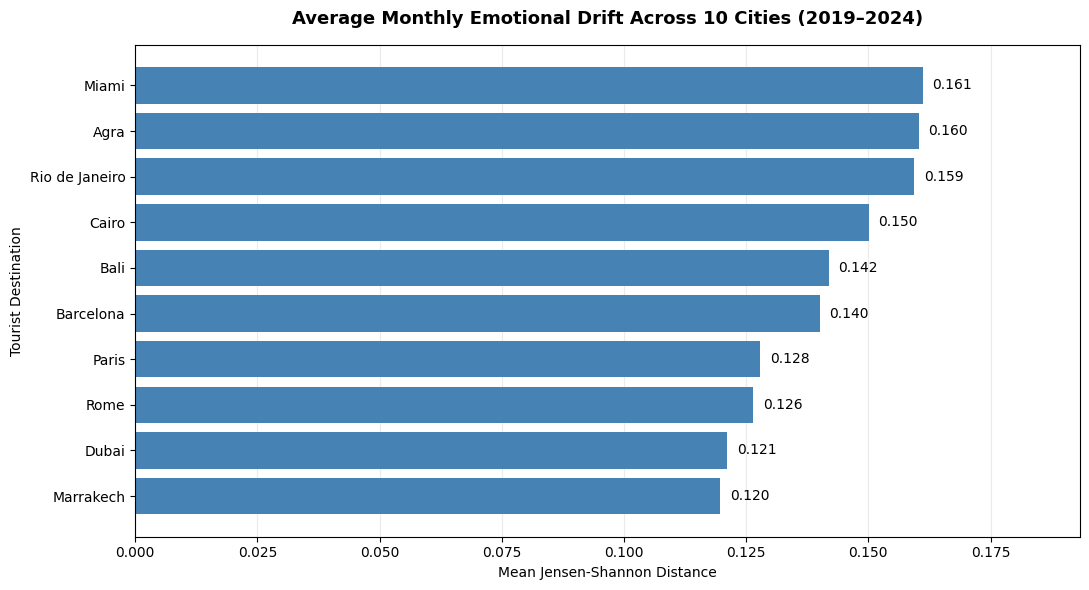

Figure 1 saved successfully.


In [4]:

# STEP 3: COMPARE AVERAGE EMOTIONAL DRIFT ACROSS CITIES

# Calculate summary statistics for each city
city_comparison = (
    drift_df.groupby("City")
    .agg(
        Valid_Transitions=("JS_Drift", "count"),
        Mean_JS_Drift=("JS_Drift", "mean"),
        Median_JS_Drift=("JS_Drift", "median"),
        Maximum_JS_Drift=("JS_Drift", "max"),
        Mean_Cosine_Drift=("Cosine_Drift", "mean")
    )
    .reset_index()
    .sort_values("Mean_JS_Drift", ascending=False)
)

# Display the summary table
display(city_comparison.round(4))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    city_comparison["City"],
    city_comparison["Mean_JS_Drift"],
    color="steelblue"
)

# Highest average drift at the top
ax.invert_yaxis()

# Display values next to each bar
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Average Monthly Emotional Drift Across 10 Cities (2019–2024)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Mean Jensen-Shannon Distance")
ax.set_ylabel("Tourist Destination")

ax.set_xlim(
    0,
    city_comparison["Mean_JS_Drift"].max() * 1.20
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# Save a high-quality image for the thesis
plt.savefig(
    figures_dir / "Figure_01_City_Emotional_Drift_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully.")



## 2. Yearly Comparison of Emotional Drift (2019–2024)

The previous graph compared the overall average emotional drift across the 10 cities.

In this section, I examine how emotional drift changed from year to year.

I calculate the average Jensen-Shannon distance for each city and year. This helps identify periods of higher emotional variation and compare patterns across destinations.

Each drift value represents a change between two consecutive months. The year is assigned according to the later month of the comparison.


In [8]:

# STEP 4: CHECK YEARLY DATA COVERAGE

yearly_counts = yearly_drift.pivot(
    index="City",
    columns="Year",
    values="Transitions"
)

print("Number of valid monthly comparisons per city and year:")
display(yearly_counts)

print("\nCity-years with fewer than 6 comparisons:")
low_coverage = yearly_drift[
    yearly_drift["Transitions"] < 6
]

display(low_coverage.sort_values(["City", "Year"]))


Number of valid monthly comparisons per city and year:


Year,2019,2020,2021,2022,2023,2024
City,,,,,,
Agra,9.0,4.0,1.0,7.0,7.0,7.0
Bali,10.0,5.0,NaN,8.0,12.0,10.0
Barcelona,6.0,4.0,5.0,10.0,9.0,12.0
Cairo,4.0,8.0,8.0,5.0,12.0,10.0
Dubai,6.0,8.0,12.0,12.0,12.0,11.0
Marrakech,6.0,2.0,4.0,9.0,12.0,12.0
Miami,11.0,6.0,12.0,12.0,10.0,12.0
Paris,NaN,9.0,7.0,10.0,8.0,10.0
Rio de Janeiro,5.0,7.0,8.0,5.0,12.0,12.0



City-years with fewer than 6 comparisons:


,City,Year,Mean_JS_Drift,Transitions
1,Agra,2020,0.183353,4
2,Agra,2021,0.200238,1
7,Bali,2020,0.107837,5
12,Barcelona,2020,0.070635,4
13,Barcelona,2021,0.156917,5
17,Cairo,2019,0.123927,4
20,Cairo,2022,0.131588,5
30,Marrakech,2020,0.087439,2
31,Marrakech,2021,0.162520,4
46,Rio de Janeiro,2019,0.146158,5


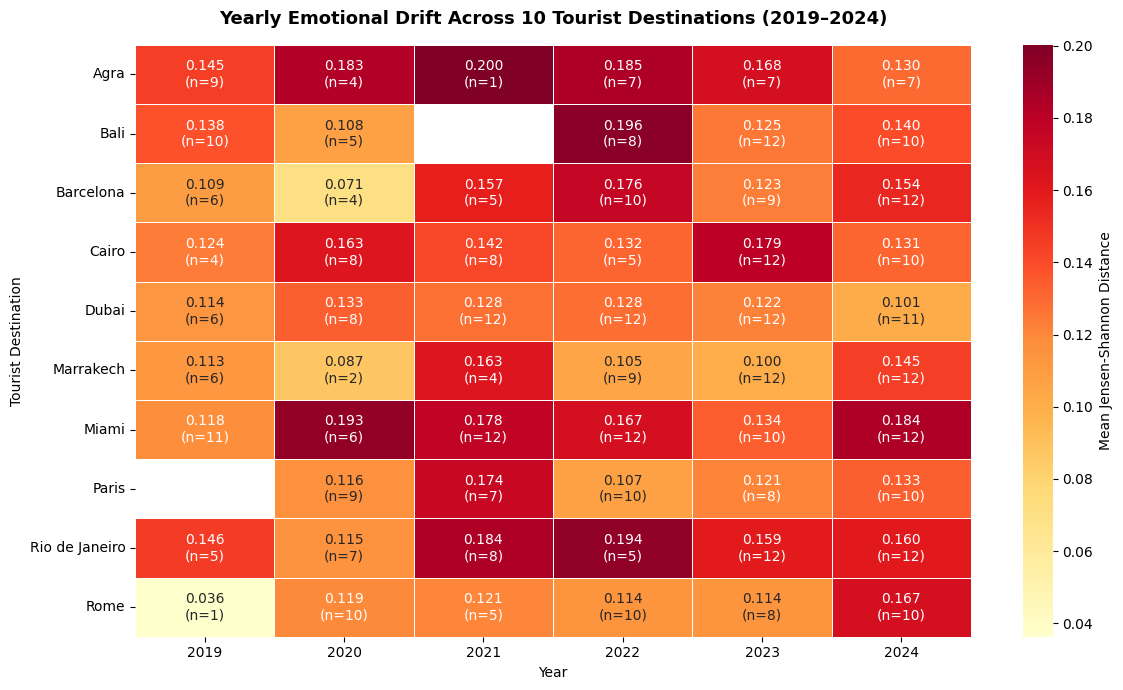

In [10]:

# STEP 5:YEARLY HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Mean drift values
heatmap_values = yearly_drift.pivot(
    index="City",
    columns="Year",
    values="Mean_JS_Drift"
)

# Number of comparisons
heatmap_counts = yearly_drift.pivot(
    index="City",
    columns="Year",
    values="Transitions"
)

# Create labels containing mean and sample size
annotations = heatmap_values.copy().astype(object)

for city in heatmap_values.index:
    for year in heatmap_values.columns:
        value = heatmap_values.loc[city, year]
        count = heatmap_counts.loc[city, year]

        if pd.isna(value):
            annotations.loc[city, year] = "No data"
        else:
            annotations.loc[city, year] = (
                f"{value:.3f}\n(n={int(count)})"
            )

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    heatmap_values,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    mask=heatmap_values.isna(),
    cbar_kws={"label": "Mean Jensen-Shannon Distance"},
    ax=ax
)

ax.set_title(
    "Yearly Emotional Drift Across 10 Tourist Destinations (2019–2024)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Tourist Destination")

plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_02_Yearly_Drift_Heatmap_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 3. Yearly Emotional Drift With a Coverage Check

Some yearly averages are based on only a few monthly comparisons. These values may not represent emotional variation across the full year.

To make the comparison more reliable, I use a minimum of six valid monthly transitions as an exploratory coverage requirement.

City-years with fewer than six comparisons are not shown in the main heatmap. They remain available in the original results.

This helps avoid giving too much importance to annual averages based on very limited observations.


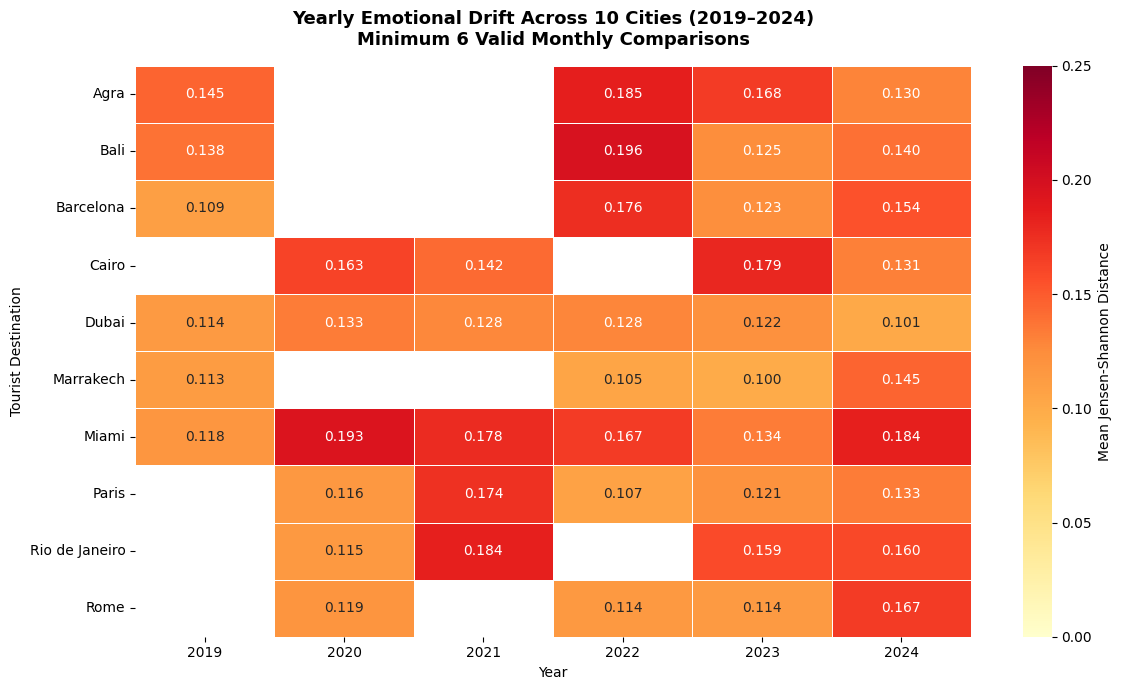

City-years retained: 45
City-years excluded: 13


In [11]:

# STEP 6: YEARLY HEATMAP WITH COVERAGE FILTER

import matplotlib.pyplot as plt
import seaborn as sns

MIN_TRANSITIONS = 6

# Keep only city-years with sufficient coverage
yearly_filtered = yearly_drift.copy()

yearly_filtered.loc[
    yearly_filtered["Transitions"] < MIN_TRANSITIONS,
    "Mean_JS_Drift"
] = float("nan")

filtered_heatmap = yearly_filtered.pivot(
    index="City",
    columns="Year",
    values="Mean_JS_Drift"
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    filtered_heatmap,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=0.25,
    cbar_kws={"label": "Mean Jensen-Shannon Distance"},
    ax=ax
)

ax.set_title(
    "Yearly Emotional Drift Across 10 Cities (2019–2024)\n"
    "Minimum 6 Valid Monthly Comparisons",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Tourist Destination")

plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_03_Yearly_Drift_Coverage_Filtered.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("City-years retained:",
      yearly_filtered["Mean_JS_Drift"].notna().sum())

print("City-years excluded:",
      yearly_filtered["Mean_JS_Drift"].isna().sum())



### Interpretation of Yearly Emotional Drift

The heatmap compares the average monthly emotional drift across 10 tourist destinations between 2019 and 2024.

The results show that emotional drift varied across both destinations and years. Bali recorded a relatively high average drift in 2022 (0.196), while Miami showed high values in 2020 (0.193) and 2024 (0.184).

Dubai showed comparatively lower emotional drift, particularly in 2024 (0.101).

To avoid interpreting yearly averages based on very limited data, only city-years with at least six valid consecutive-month comparisons were included in this figure.

The blank cells represent city-years with insufficient valid comparisons.

These findings indicate changes in the distribution of emotions expressed in TripAdvisor reviews. They do not necessarily indicate an improvement or decline in tourist satisfaction.

Differences in review volume, attraction coverage and other sampling factors may also influence the observed patterns.


### 4. Monthly Emotional Drift Trends Across Tourist Destinations (2019–2024)

This analysis examines how tourist emotions changed from month to month in ten destinations between 2019 and 2024.

Jensen–Shannon distance is used to measure the difference between consecutive monthly emotion distributions. Higher values indicate greater changes in the emotion profiles.

The purpose of this visualization is to identify periods of emotional variation and compare temporal patterns across destinations. Only consecutive months meeting the minimum requirement of 10 reviews per month are included.

Missing points indicate months without an eligible consecutive-month comparison. They should not be interpreted as zero emotional drift.

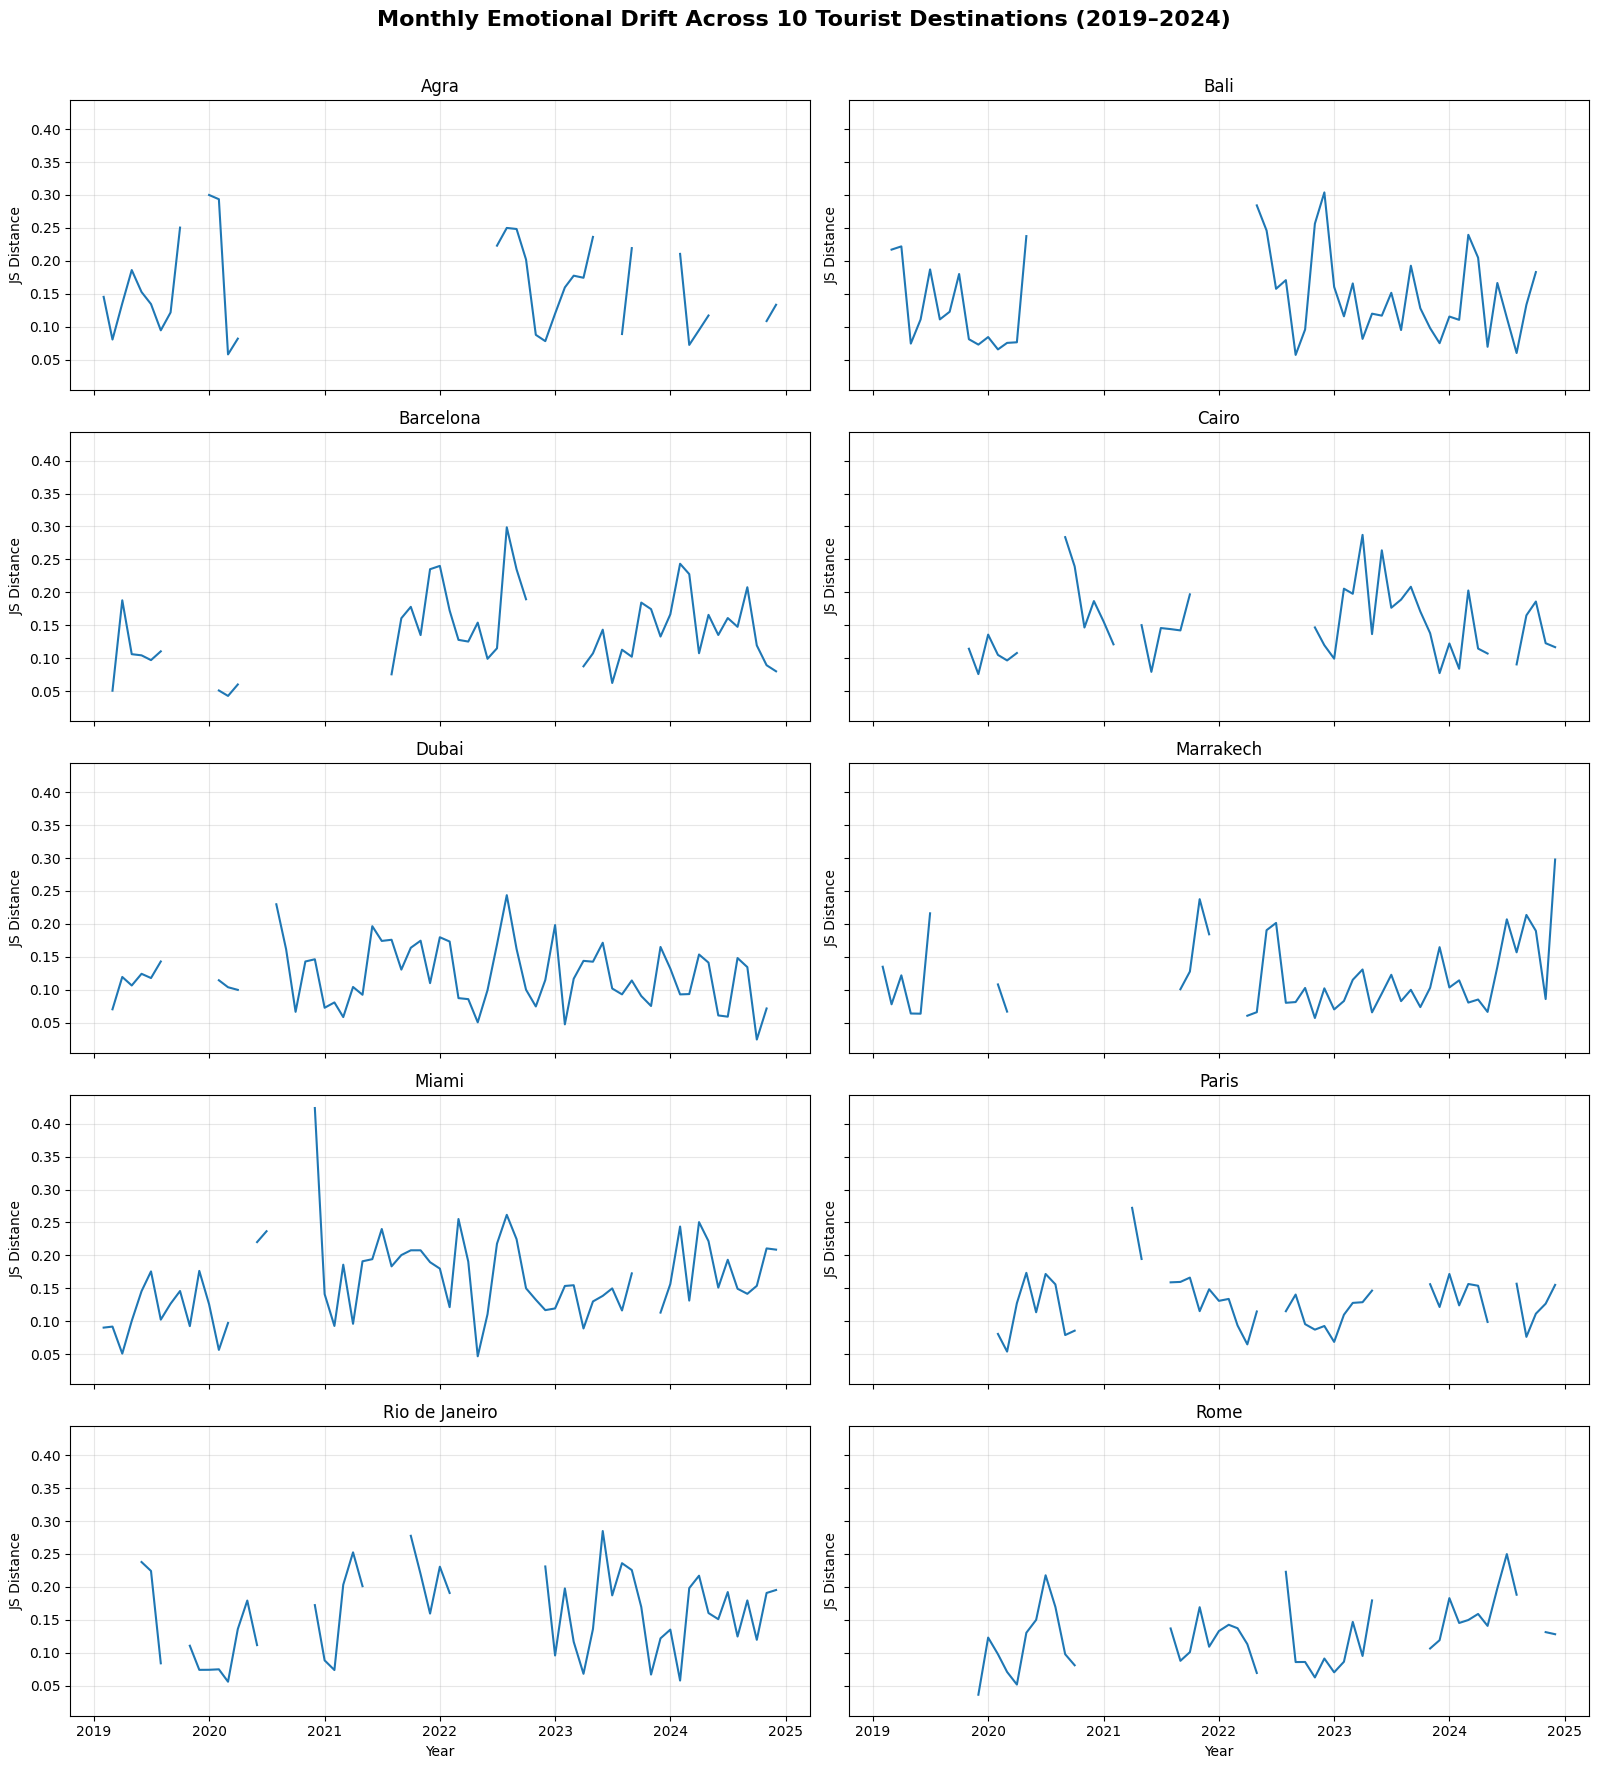

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare the existing drift dataset
plot_df = drift_df.copy()

plot_df["Month_Year"] = pd.to_datetime(
    plot_df["Month_Year"]
)

# Use only eligible consecutive-month comparisons
plot_df = plot_df[
    (plot_df["Month_Gap"] == 1) &
    (plot_df["Review_Count"] >= 10) &
    (plot_df["Previous_Review_Count"] >= 10)
].copy()

cities = sorted(plot_df["City"].unique())

# Full calendar range
all_months = pd.date_range(
    "2019-01-01", "2024-12-01", freq="MS"
)

fig, axes = plt.subplots(
    5, 2, figsize=(16, 18), sharex=True, sharey=True
)

for ax, city in zip(axes.flat, cities):
    city_data = (
        plot_df[plot_df["City"] == city]
        .set_index("Month_Year")
        .reindex(all_months)
    )

    ax.plot(
        city_data.index,
        city_data["JS_Drift"],
        linewidth=1.5
    )

    ax.set_title(city, fontsize=12)
    ax.set_ylabel("JS Distance")
    ax.grid(alpha=0.3)

for ax in axes[-1]:
    ax.set_xlabel("Year")

fig.suptitle(
    "Monthly Emotional Drift Across 10 Tourist Destinations (2019–2024)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    figures_dir / "Monthly_Drift_Trends_10_Cities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation: Monthly Emotional Drift Across Ten Destinations

The figure 2 shows monthly changes in tourist emotion profiles across ten destinations between 2019 and 2024.

The results indicate that emotional drift varies across destinations and over time. Miami shows a particularly large change in December 2020, while Marrakech shows a notable increase in emotional drift in December 2024. These periods correspond to the two extreme drift episodes identified in the previous analysis.

Other destinations, including Barcelona, Cairo and Rio de Janeiro, also show periods of increased emotional variation. However, not all visible peaks meet the statistical criteria for an extreme drift episode.

Some months are not connected because there were insufficient reviews or no valid consecutive-month comparison.

Overall, the visualization demonstrates that tourist emotion profiles are not constant over time. However, emotional drift alone does not explain why these changes occurred. Review counts, attraction composition, visitor ratings and external events must also be considered.

### 5. Monthly Review Volume Across Tourist Destinations (2019–2024)

This figure shows the number of TripAdvisor reviews collected each month for ten tourist destinations between 2019 and 2024.

The purpose is to understand how review availability changed over time and identify periods with limited data.

In the emotional drift analysis, a minimum of 10 reviews per city per month was required. Months with fewer than 10 reviews were excluded from the primary drift comparisons.

This visualization uses all observed city-month review counts, including months below the threshold. It helps explain why some periods are missing from the emotional drift graphs and highlights potential limitations caused by small sample sizes.

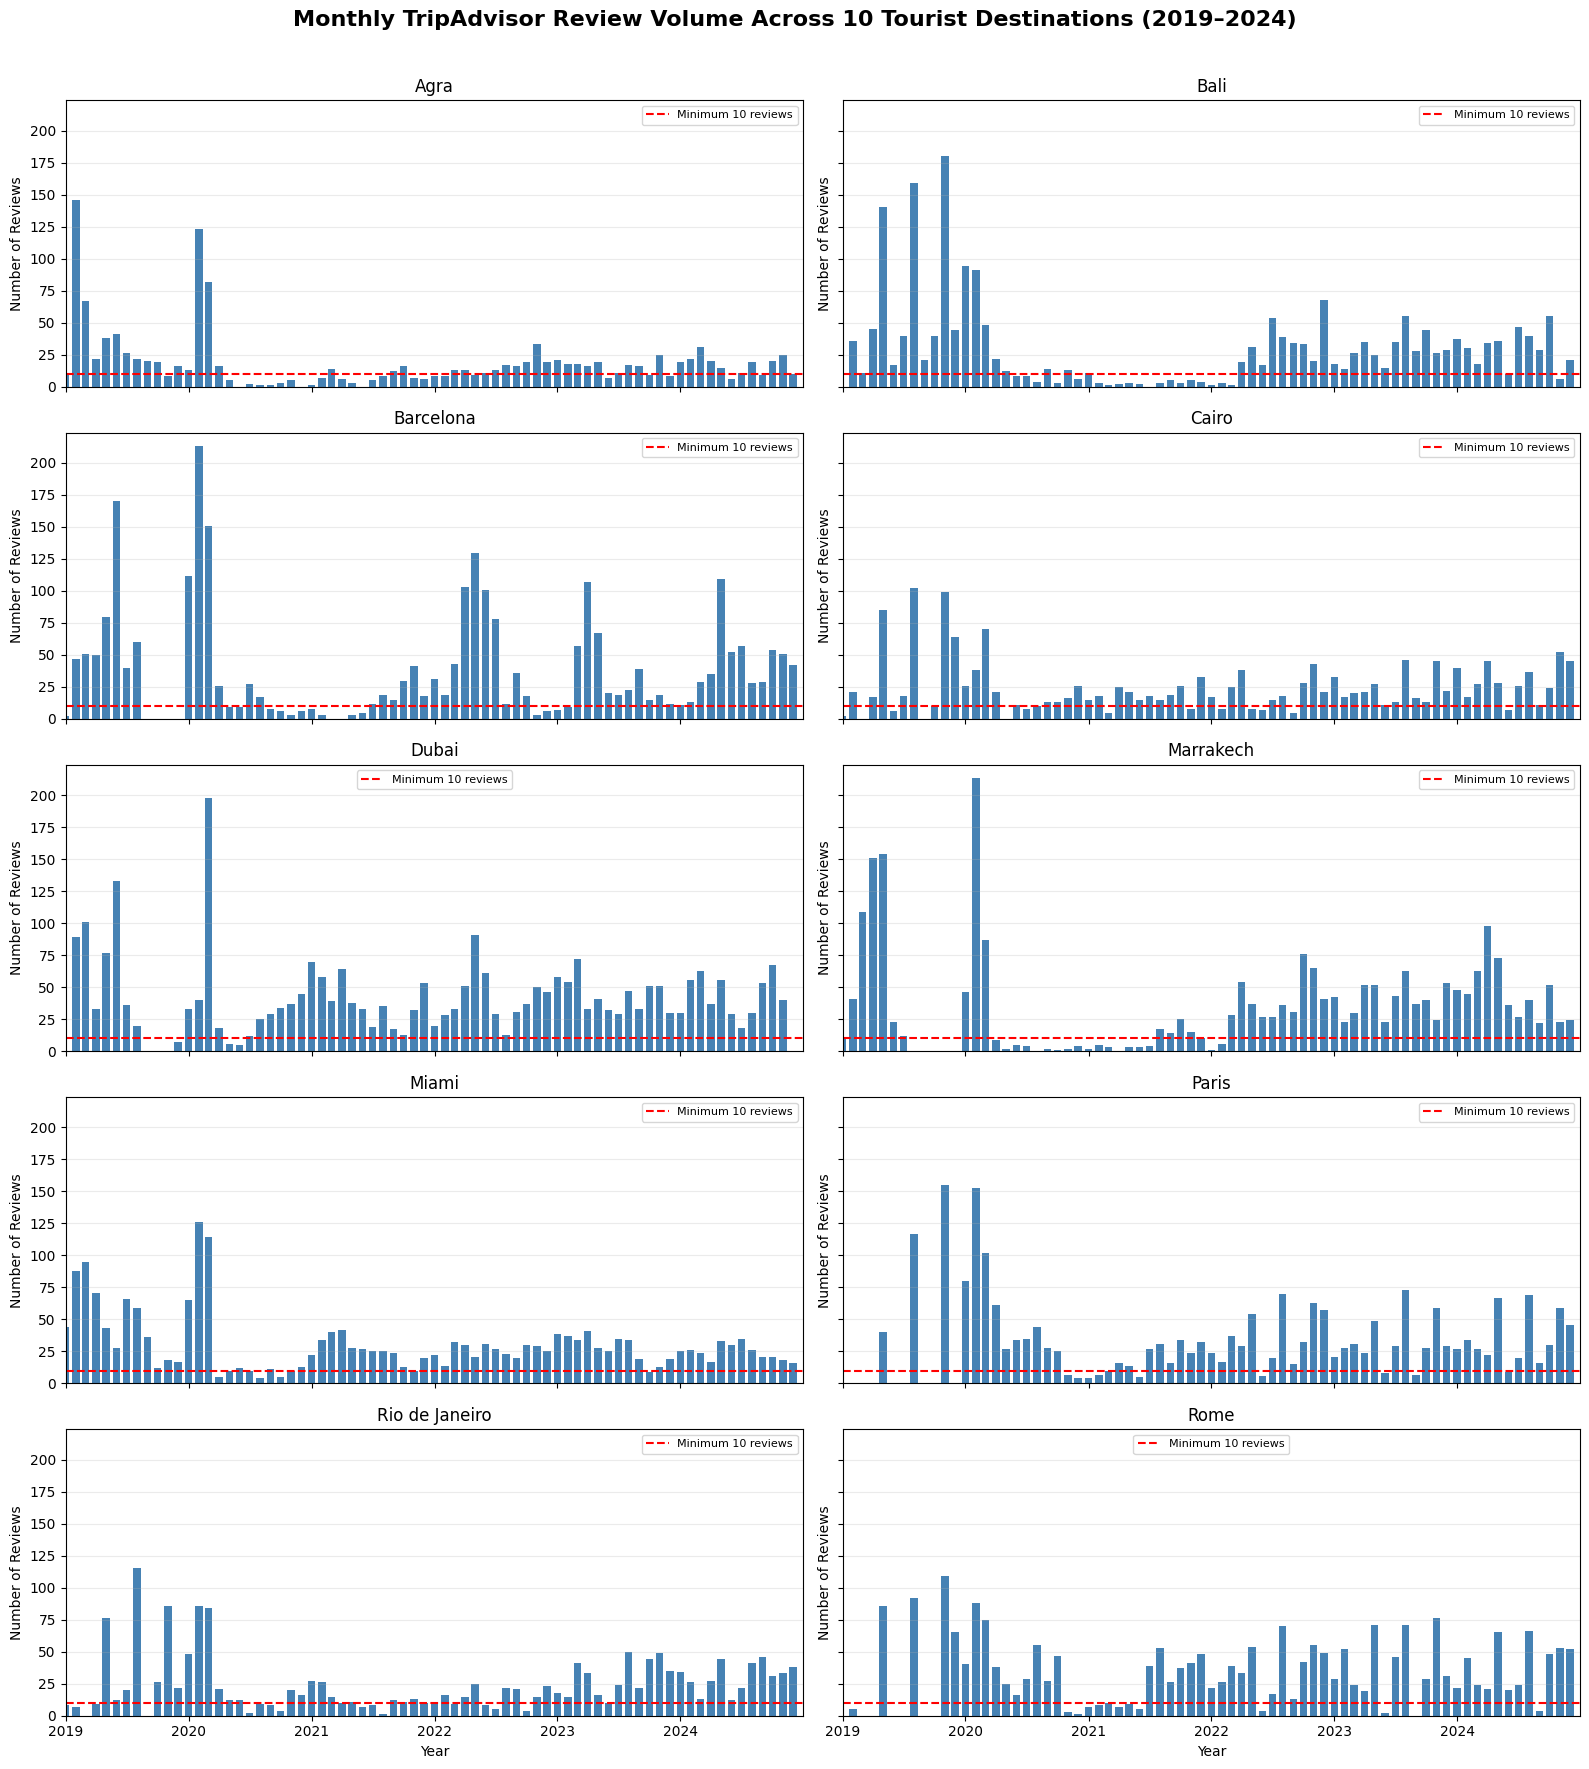

In [16]:

# STEP 5: MONTHLY REVIEW VOLUME ACROSS 10 CITIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load monthly review counts
volume_df = pd.read_csv(
    results_dir / "Monthly_Emotion_Profiles.csv"
)

volume_df["Month_Year"] = pd.to_datetime(
    volume_df["Month_Year"]
)

cities = sorted(volume_df["City"].unique())

# Complete study period
all_months = pd.date_range(
    "2019-01-01",
    "2024-12-01",
    freq="MS"
)

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18),
    sharex=True,
    sharey=True

)

for ax, city in zip(axes.flat, cities):

    city_data = (
        volume_df[volume_df["City"] == city]
        .set_index("Month_Year")
        .reindex(all_months)
    )

    # Review counts; missing months remain NaN
    ax.bar(
        city_data.index,
        city_data["Review_Count"],
        width=22,
        color="steelblue"
    )

    # Primary minimum review threshold
    ax.axhline(
        y=10,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Minimum 10 reviews"
    )

    ax.set_title(city, fontsize=12)
    ax.set_ylabel("Number of Reviews")
    ax.grid(axis="y", alpha=0.25)

    ax.set_xlim(
        pd.Timestamp("2019-01-01"),
        pd.Timestamp("2024-12-31")
    )

    ax.xaxis.set_major_locator(
        mdates.YearLocator()
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

    ax.legend(fontsize=8)

for ax in axes[-1]:
    ax.set_xlabel("Year")

fig.suptitle(
    "Monthly TripAdvisor Review Volume Across 10 Tourist Destinations (2019–2024)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    figures_dir / "Monthly_Review_Volume_10_Cities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation: Monthly Review Volume Across Tourist Destinations

The figure 3 presents the monthly distribution of collected TripAdvisor reviews across ten tourist destinations from 2019 to 2024.

Review availability varies considerably across cities and years. Several destinations have relatively high review counts during 2019 and early 2020, followed by periods of reduced coverage during 2020 and 2021. Review availability generally improves in later years, although the recovery pattern differs between destinations.

The red dashed line indicates the minimum requirement of 10 reviews per city-month used in the primary emotional drift analysis. Months below this threshold were excluded from the primary comparisons.

These differences in review volume are important because monthly emotion distributions estimated from small samples may be less stable. The figure therefore provides context for interpreting emotional drift and understanding gaps in the time-series analysis.

The observed review counts reflect the collected dataset and should not be interpreted as direct measurements of overall tourism activity.

### 6. Average Emotion Distribution Across Tourist Destinations

This analysis compares seven emotions across ten tourist destinations between 2019 and 2024: Anger, Disgust, Fear, Joy, Neutral, Sadness and Surprise.

The emotion scores were obtained using the DistilRoBERTa emotion classification model.

We calculate review-count-weighted average emotion probabilities for each destination. This ensures that months containing more reviews contribute proportionally more to the city-level results.

The purpose is to identify differences in the overall emotional composition of tourist reviews across destinations. These results describe the collected review dataset rather than the emotions of all visitors.

Emotion probability totals:
City
Agra              1.0
Bali              1.0
Barcelona         1.0
Cairo             1.0
Dubai             1.0
Marrakech         1.0
Miami             1.0
Paris             1.0
Rio de Janeiro    1.0
Rome              1.0
dtype: float64


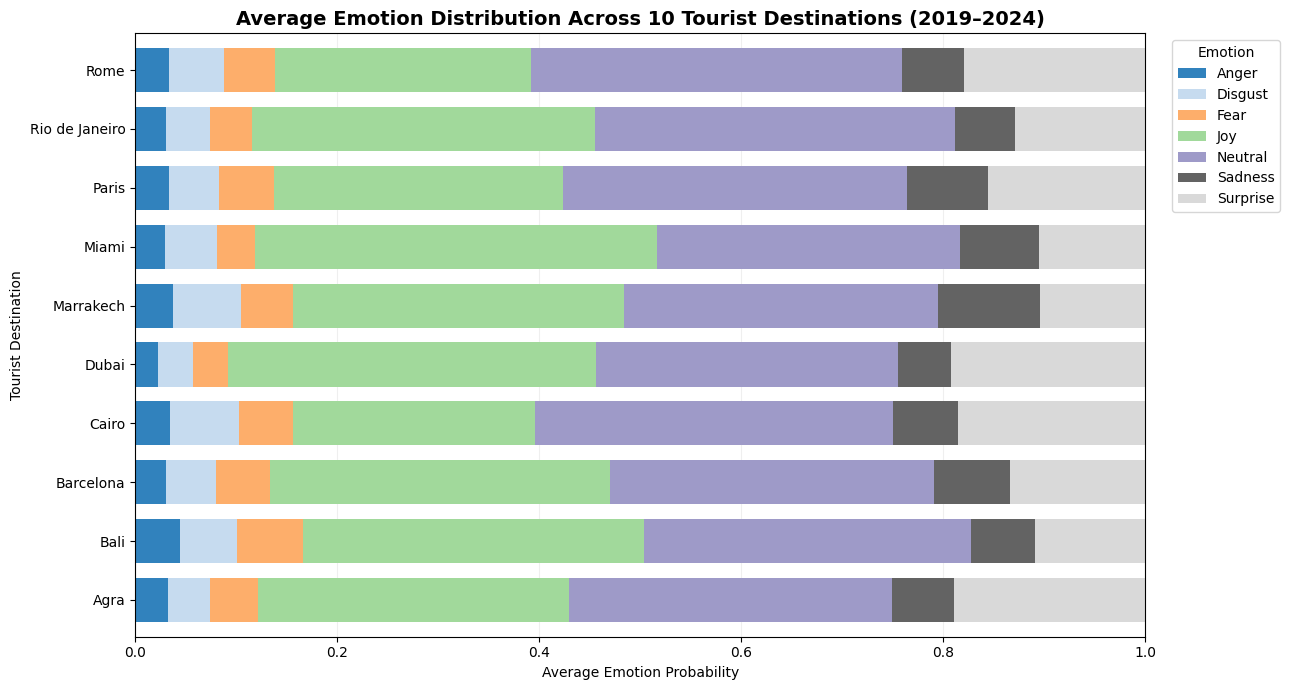

In [18]:

# AVERAGE EMOTION DISTRIBUTION BY CITY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

monthly_emotions = pd.read_csv(
    results_dir / "Monthly_Emotion_Profiles.csv"
)

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

# Weighted average based on monthly review counts
city_emotions = monthly_emotions.groupby("City").apply(
    lambda group: pd.Series({
        emotion: np.average(
            group[emotion],
            weights=group["Review_Count"]
        )
        for emotion in emotion_cols
    }),
    include_groups=False
)

# Verify that each city's probabilities sum to approximately 1
print("Emotion probability totals:")
print(city_emotions.sum(axis=1).round(4))

# Plot stacked horizontal bars
ax = city_emotions[emotion_cols].plot(
    kind="barh",
    stacked=True,
    figsize=(13, 7),
    colormap="tab20c",
    width=0.75
)

ax.set_title(
    "Average Emotion Distribution Across 10 Tourist Destinations (2019–2024)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Average Emotion Probability")
ax.set_ylabel("Tourist Destination")
ax.set_xlim(0, 1)

ax.legend(
    title="Emotion",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figures_dir / "Average_Emotion_Distribution_10_Cities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of Figure 6: Average Emotion Distribution

Figure 4 presents the average distribution of seven predicted emotions across ten tourist destinations from 2019 to 2024.

Joy and Neutral represent the largest proportions in most destinations. Miami shows a relatively high proportion of Joy, while Rome has a larger Neutral component. Other emotions, including Anger, Disgust and Fear, generally have smaller contributions.

These differences suggest that the emotional composition of TripAdvisor reviews varies between destinations.

However, the graph represents average emotion probabilities across the full study period. It does not show how emotions changed over time. Monthly emotional drift is therefore examined separately using Jensen–Shannon distance.

The results should also be interpreted with caution because the dataset consists of collected TripAdvisor reviews and may not represent all tourists visiting these destinations.

In [19]:

# Table: Average emotion probabilities for each city

emotion_summary = city_emotions[emotion_cols].round(3)

display(emotion_summary)

# Save table for thesis reporting
emotion_summary.to_csv(
    results_dir / "City_Average_Emotion_Distribution.csv"
)

print("Emotion summary table saved successfully.")


,Anger,Disgust,Fear,Joy,Neutral,Sadness,Surprise
City,,,,,,,
Agra,0.032,0.042,0.048,0.308,0.320,0.061,0.190
Bali,0.045,0.056,0.065,0.338,0.324,0.063,0.109
Barcelona,0.030,0.049,0.054,0.336,0.321,0.076,0.134
Cairo,0.035,0.068,0.054,0.240,0.354,0.065,0.185
Dubai,0.022,0.035,0.034,0.364,0.300,0.052,0.192
Marrakech,0.037,0.068,0.051,0.328,0.310,0.101,0.104
Miami,0.029,0.052,0.038,0.399,0.300,0.078,0.106
Paris,0.033,0.049,0.055,0.287,0.340,0.081,0.155
Rio de Janeiro,0.030,0.044,0.041,0.340,0.356,0.060,0.129


Emotion summary table saved successfully.


### Figure: Yearly Emotion Trends Across Tourist Destinations (2019–2024)

This analysis examines how the seven predicted emotions changed between 2019 and 2024.

The purpose is to identify general changes in the emotional composition of TripAdvisor reviews over time.

Yearly emotion probabilities are calculated using the number of reviews in each city-month as weights. This prevents months with very few reviews from having the same influence as months with many reviews.

The results provide a broader view of emotional changes before examining individual monthly drift episodes.

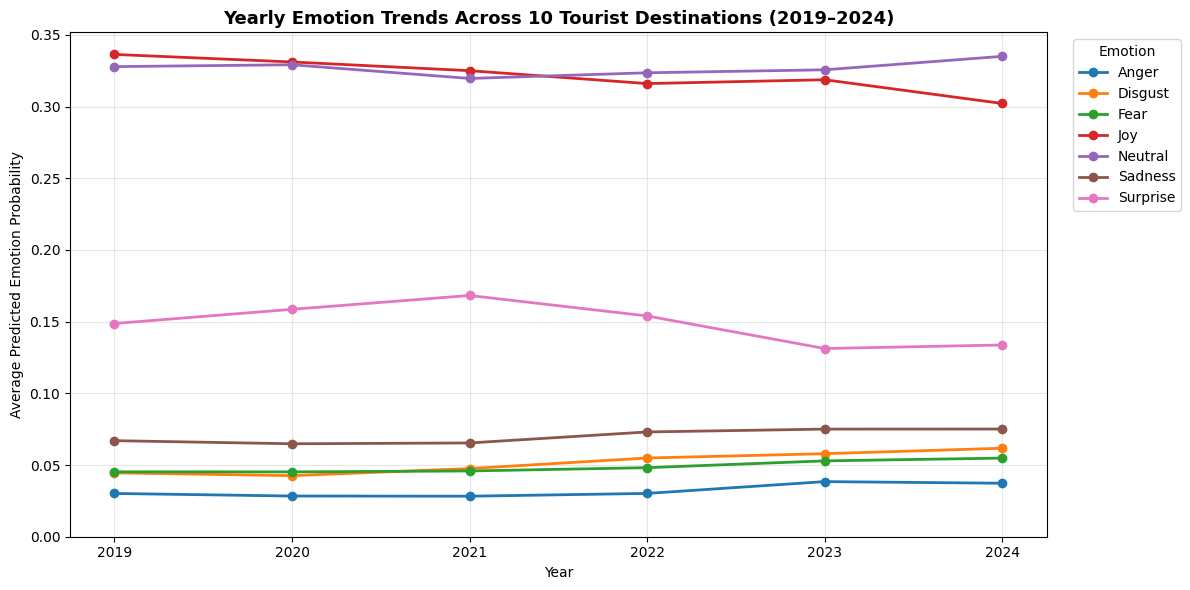

,Year,Review_Count,Anger,Disgust,Fear,Joy,Neutral,Sadness,Surprise
0,2019,4715,0.030,0.045,0.045,0.336,0.328,0.067,0.149
1,2020,4021,0.028,0.043,0.045,0.331,0.329,0.065,0.159
2,2021,2042,0.028,0.048,0.046,0.325,0.320,0.065,0.168
3,2022,3557,0.030,0.055,0.048,0.316,0.324,0.073,0.154
4,2023,3752,0.038,0.058,0.053,0.319,0.326,0.075,0.131
5,2024,3998,0.037,0.062,0.055,0.302,0.335,0.075,0.134


In [21]:

import pandas as pd
import matplotlib.pyplot as plt

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

# Prepare monthly dataset
yearly_df = pd.read_csv(
    results_dir / "Monthly_Emotion_Profiles.csv"
)

yearly_df["Month_Year"] = pd.to_datetime(
    yearly_df["Month_Year"]
)

yearly_df["Year"] = yearly_df["Month_Year"].dt.year

# Calculate review-weighted yearly emotion probabilities
yearly_rows = []

for year, group in yearly_df.groupby("Year"):
    total_reviews = group["Review_Count"].sum()

    if total_reviews == 0:
        continue

    row = {"Year": year, "Review_Count": total_reviews}

    for emotion in emotion_cols:
        row[emotion] = (
            group[emotion] * group["Review_Count"]
        ).sum() / total_reviews

    yearly_rows.append(row)

yearly_emotions = pd.DataFrame(yearly_rows).sort_values("Year")

# Plot all seven emotions
plt.figure(figsize=(12, 6))

for emotion in emotion_cols:
    plt.plot(
        yearly_emotions["Year"],
        yearly_emotions[emotion],
        marker="o",
        linewidth=2,
        label=emotion
    )

plt.title(
    "Yearly Emotion Trends Across 10 Tourist Destinations (2019–2024)",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Average Predicted Emotion Probability")
plt.xticks(range(2019, 2025))
plt.ylim(bottom=0)
plt.legend(title="Emotion", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure7_Yearly_Emotion_Trends.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(yearly_emotions.round(3))


### Interpretation of Figure 5: Yearly Emotion Trends (2019–2024)

Figure 5 shows how the average predicted emotion probabilities changed across ten tourist destinations between 2019 and 2024.

Joy and Neutral remained the two largest emotion components throughout the study period. Joy showed a gradual decrease, while Neutral increased slightly and became the largest component in 2024.

Surprise increased between 2019 and 2021 before declining in the following years. Anger, Disgust, Fear and Sadness remained relatively low, with some small variations.

These results suggest that the emotional composition of the collected TripAdvisor reviews changed over time. However, the yearly averages combine all ten destinations and may be influenced by differences in review volume and destination representation.

Therefore, the findings should be interpreted as descriptive trends rather than evidence that external events directly caused changes in tourist emotions.

Monthly emotional-drift analysis provides a more detailed examination of when and where these changes occurred.

### Figure 6: Yearly Joy and Neutral Emotion Trends by Destination (2019–2024)

This analysis compares the yearly changes in Joy and Neutral emotion probabilities across ten tourist destinations.

The aim is to understand whether the overall emotional trends observed in Figure 7 are also present in individual cities.

Yearly emotion probabilities are calculated using review-count-weighted averages. This gives more weight to months containing more reviews.

The comparison helps identify differences between destinations and provides a clearer understanding of how emotional patterns changed over the study period.

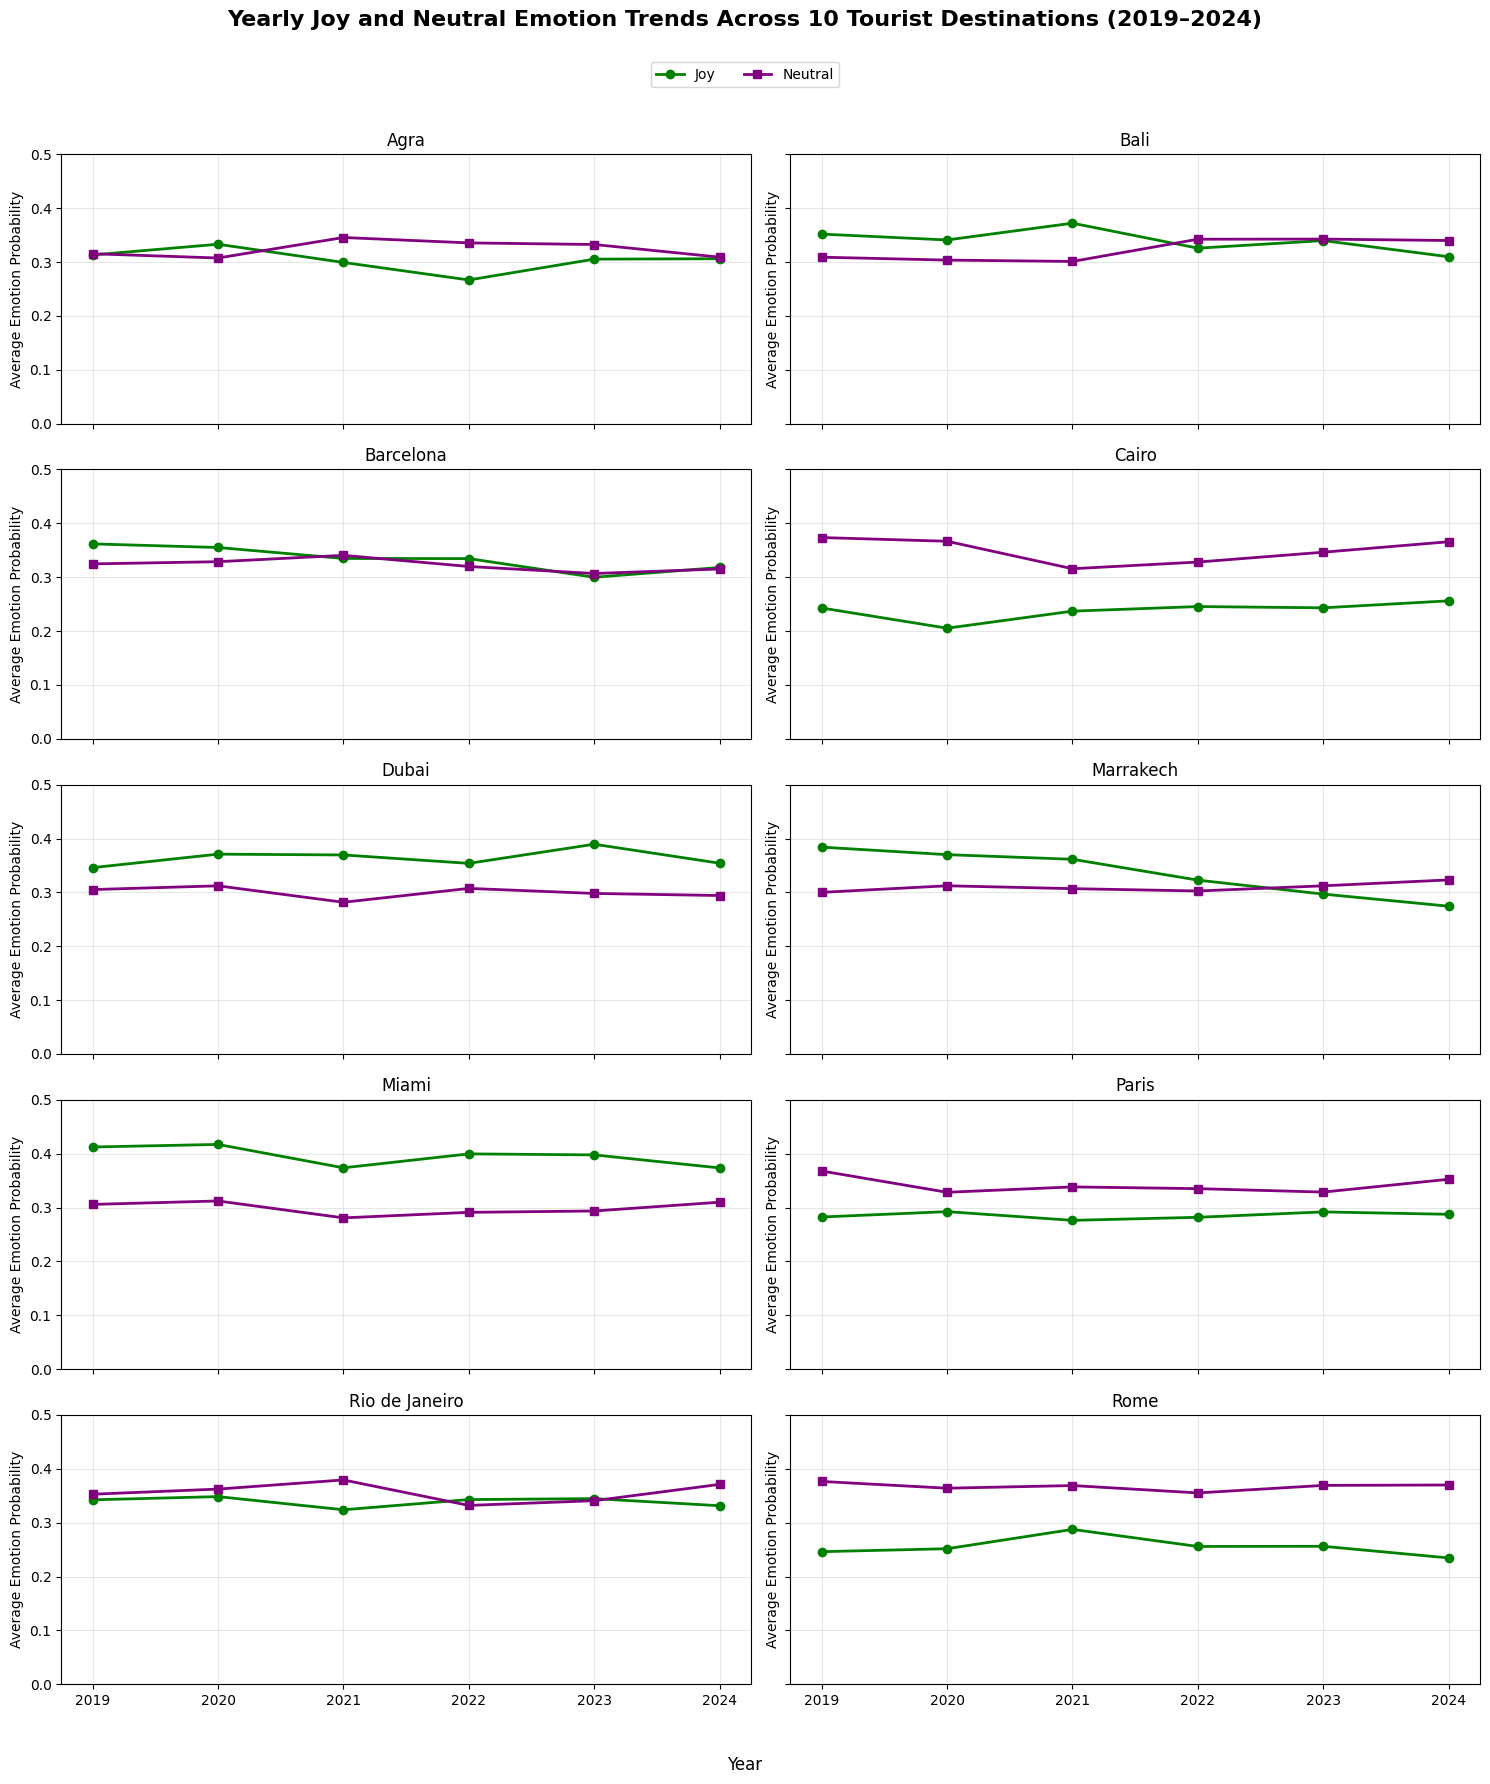

Figure 6 saved successfully.
Yearly city emotion table saved successfully.


,City,Year,Review_Count,Joy,Neutral
0,Agra,2019,435,0.313,0.315
1,Agra,2020,251,0.333,0.308
2,Agra,2021,85,0.299,0.346
3,Agra,2022,179,0.267,0.336
4,Agra,2023,185,0.305,0.333
5,Agra,2024,207,0.306,0.309
6,Bali,2019,733,0.352,0.309
7,Bali,2020,323,0.341,0.304
8,Bali,2021,42,0.372,0.301
9,Bali,2022,320,0.326,0.342


In [39]:

# ==========================================================
# FIGURE 6: YEARLY JOY AND NEUTRAL TRENDS BY CITY
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load existing monthly emotion profiles
city_year_df = pd.read_csv(
    results_dir / "Monthly_Emotion_Profiles.csv"
)

# Prepare year
city_year_df["Month_Year"] = pd.to_datetime(
    city_year_df["Month_Year"]
)

city_year_df["Year"] = city_year_df["Month_Year"].dt.year

# Calculate review-weighted yearly emotion probabilities
yearly_city_rows = []

for (city, year), group in city_year_df.groupby(["City", "Year"]):

    total_reviews = group["Review_Count"].sum()

    if total_reviews == 0:
        continue

    joy = np.average(
        group["Joy"],
        weights=group["Review_Count"]
    )

    neutral = np.average(
        group["Neutral"],
        weights=group["Review_Count"]
    )

    yearly_city_rows.append({
        "City": city,
        "Year": year,
        "Review_Count": total_reviews,
        "Joy": joy,
        "Neutral": neutral
    })

yearly_city = pd.DataFrame(yearly_city_rows)

# Sort cities
cities = sorted(yearly_city["City"].unique())

# Create 10 city panels
fig, axes = plt.subplots(
    5, 2,
    figsize=(15, 18),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, city in zip(axes, cities):

    city_data = yearly_city[
        yearly_city["City"] == city
    ].sort_values("Year")

    ax.plot(
        city_data["Year"],
        city_data["Joy"],
        marker="o",
        linewidth=2,
        color="green",
        label="Joy"
    )

    ax.plot(
        city_data["Year"],
        city_data["Neutral"],
        marker="s",
        linewidth=2,
        color="purple",
        label="Neutral"
    )

    ax.set_title(city, fontsize=12)
    ax.set_xticks(range(2019, 2025))
    ax.set_ylim(0, 0.5)
    ax.set_ylabel("Average Emotion Probability")
    ax.grid(alpha=0.3)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.965)
)

fig.suptitle(
    "Yearly Joy and Neutral Emotion Trends Across "
    "10 Tourist Destinations (2019–2024)",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

fig.supxlabel("Year")

plt.tight_layout(rect=[0, 0.02, 1, 0.95])

# Save figure
plt.savefig(
    figures_dir / "Figure8_Yearly_Joy_Neutral_By_City.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
yearly_city.to_csv(
    results_dir / "Yearly_City_Joy_Neutral_Trends.csv",
    index=False
)

print("Figure 6 saved successfully.")
print("Yearly city emotion table saved successfully.")

display(yearly_city.head(10).round(3))


### Interpretation of Figure 6: Yearly Joy and Neutral Trends by Destination

Figure 8 compares the yearly average predicted probabilities of Joy and Neutral across ten tourist destinations between 2019 and 2024.

The results show that emotional patterns differ between destinations. Miami and Dubai maintained higher Joy probabilities than Neutral throughout the study period. In contrast, Rome and Cairo consistently showed higher Neutral probabilities.

Marrakech showed a gradual decrease in Joy, while Neutral increased slightly. Barcelona and Agra displayed smaller differences between the two emotions.

These findings suggest that the overall emotional trends observed in Figure 7 are not equally represented across all destinations. Some cities showed relatively stable emotional patterns, while others experienced changes in the balance between Joy and Neutral.

However, yearly averages can hide short-term emotional changes. The monthly emotional-drift analysis is therefore necessary to identify more specific periods of change.

These results are descriptive and do not establish the causes of the observed differences.

### Figure 7: Emotion Changes During the Two Extreme Drift Episodes

This figure examines the changes in predicted emotion probabilities during the two extreme emotional-drift episodes identified in the study.

The first episode occurred in Miami between November and December 2020. The second occurred in Marrakech between November and December 2024.

Both episodes were detected using Jensen–Shannon distance and a city-specific Robust Z-score greater than 3.5.

For each city, the seven emotion probabilities are compared between the previous month and the month in which the drift was detected.

The purpose is to identify which emotions contributed to the observed changes. These comparisons describe changes in the collected reviews and do not establish that an external event caused the emotional drift.

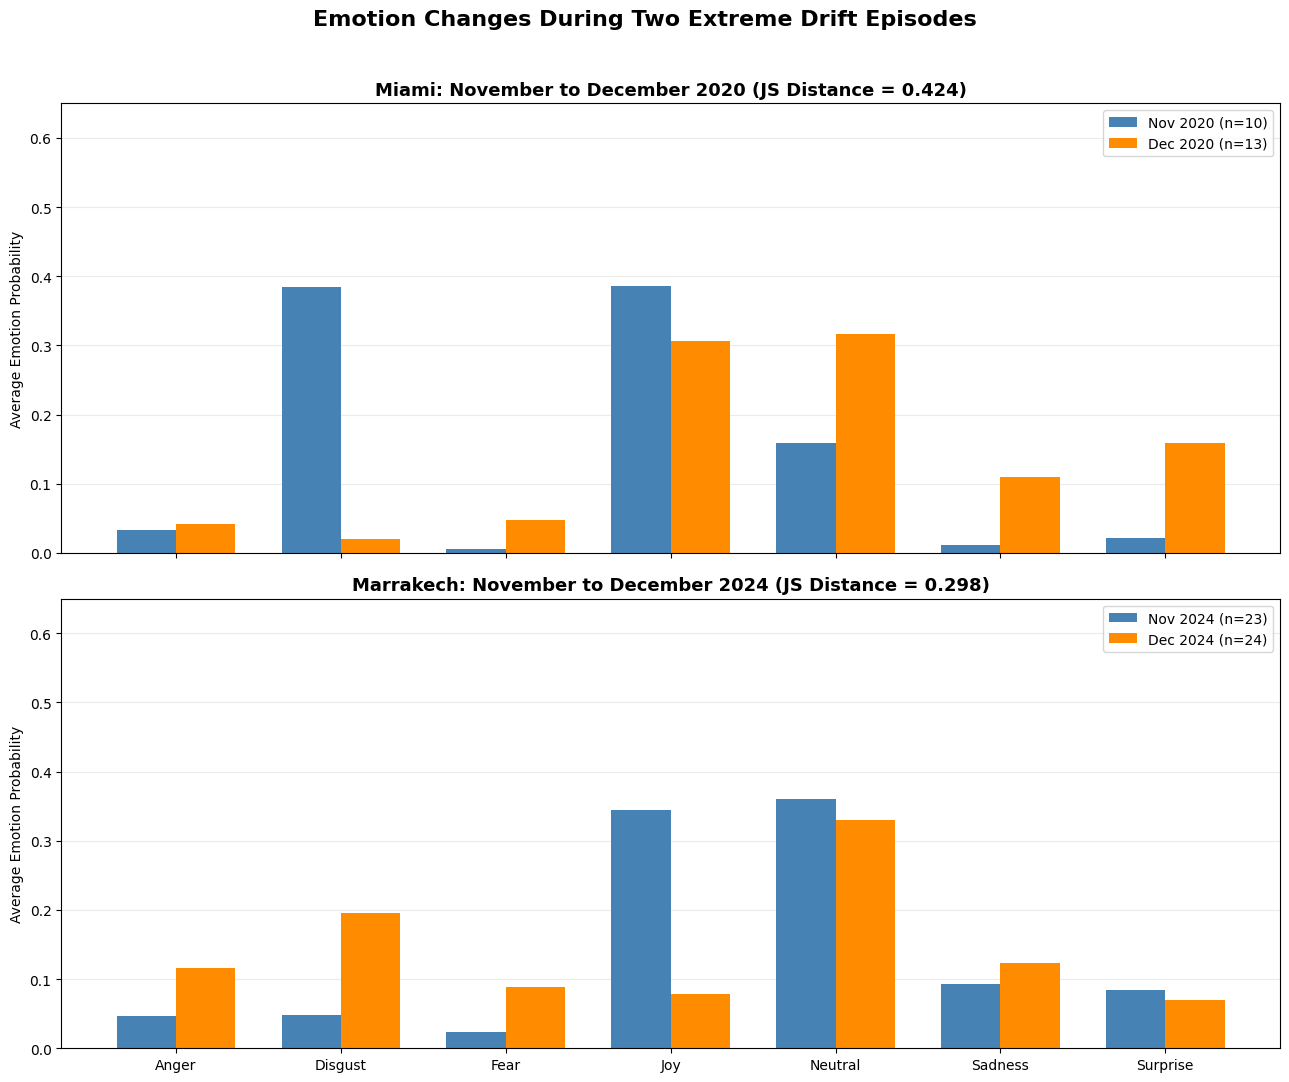

Figure 7 saved successfully.


In [41]:

# ==========================================================
# FIGURE 7: EMOTION CHANGES DURING EXTREME DRIFT EPISODES
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load monthly emotion profiles
monthly_data = pd.read_csv(
    results_dir / "Monthly_Emotion_Profiles.csv"
)

monthly_data["Month_Year"] = pd.to_datetime(
    monthly_data["Month_Year"]
)

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

# Extreme drift episodes identified in the analysis
episodes = [
    {
        "city": "Miami",
        "previous": "2020-11",
        "current": "2020-12",
        "js": 0.423731
    },
    {
        "city": "Marrakech",
        "previous": "2024-11",
        "current": "2024-12",
        "js": 0.297725
    }
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 11),
    sharex=True
)

x = np.arange(len(emotion_cols))
width = 0.36

for ax, episode in zip(axes, episodes):

    city = episode["city"]

    previous_date = pd.Timestamp(
        episode["previous"]
    )

    current_date = pd.Timestamp(
        episode["current"]
    )

    previous_data = monthly_data[
        (monthly_data["City"] == city) &
        (monthly_data["Month_Year"] == previous_date)
    ]

    current_data = monthly_data[
        (monthly_data["City"] == city) &
        (monthly_data["Month_Year"] == current_date)
    ]

    if len(previous_data) != 1 or len(current_data) != 1:
        raise ValueError(
            f"Expected one monthly profile per month for {city}."
        )

    previous_values = previous_data[
        emotion_cols
    ].iloc[0].to_numpy(dtype=float)

    current_values = current_data[
        emotion_cols
    ].iloc[0].to_numpy(dtype=float)

    previous_count = int(
        previous_data["Review_Count"].iloc[0]
    )

    current_count = int(
        current_data["Review_Count"].iloc[0]
    )

    # Previous month
    ax.bar(
        x - width / 2,
        previous_values,
        width,
        label=f"{previous_date:%b %Y} (n={previous_count})",
        color="steelblue"
    )

    # Current month
    ax.bar(
        x + width / 2,
        current_values,
        width,
        label=f"{current_date:%b %Y} (n={current_count})",
        color="darkorange"
    )

    ax.set_title(
        f"{city}: {previous_date:%B} to "
        f"{current_date:%B %Y} "
        f"(JS Distance = {episode['js']:.3f})",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel("Average Emotion Probability")
    ax.set_ylim(0, 0.65)
    ax.set_xticks(x)
    ax.set_xticklabels(emotion_cols)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Emotion Changes During Two Extreme Drift Episodes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save figure
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "Figure9_Extreme_Drift_Emotion_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 7 saved successfully.")


### Interpretation of Figure 7

Figure 7 compares the seven predicted emotion probabilities during the two extreme emotional-drift episodes identified in Miami and Marrakech.

In Miami, the transition from November to December 2020 shows a substantial decrease in Disgust, together with increases in Neutral, Sadness and Surprise. The Jensen–Shannon distance was 0.424, indicating a large change in the monthly emotion distribution. However, the comparison involved only 10 and 13 reviews, so sampling variation may have influenced the result.

In Marrakech, the transition from November to December 2024 shows a clear decrease in Joy and increases in Disgust, Anger and Fear. The Jensen–Shannon distance was 0.298. The monthly review counts were relatively similar, with 23 reviews in November and 24 in December.

These findings show that extreme emotional drift can involve different types of emotional changes. Miami experienced a redistribution across several emotions, while Marrakech showed a stronger shift away from Joy toward more negative emotions.

The results describe changes in predicted emotion probabilities rather than confirmed changes in tourist satisfaction. Further analysis of review content, attraction composition and external events is required to interpret these episodes.

## Figure 8: External-Event Association of Emotional-Drift Episodes

This figure presents the results of the external-event mapping analysis for the 12 detected emotional-drift episodes across tourist destinations.

The episodes were classified into three categories: moderate association, weak association, and no identifiable external association.

The purpose of this visualization is to examine how often detected emotional changes were accompanied by relevant external events. These associations provide useful context but do not prove that external events caused the emotional changes.

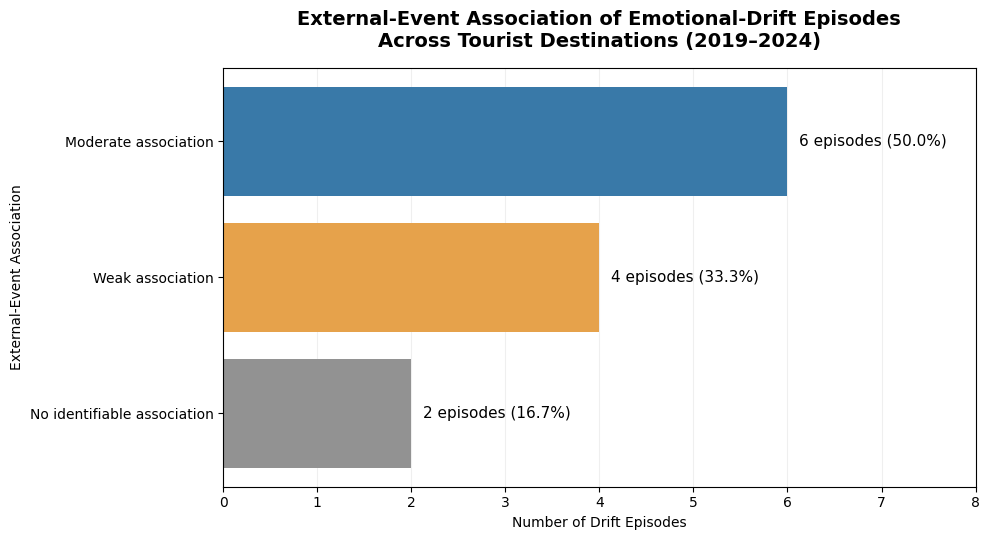

Figure saved: c:\Users\vidya\OneDrive\Documents\GitHub\sentiment-drift-analysis-tourism-reviews\figures\final_thesis\Figure10_Event_Association.png


In [42]:

import pandas as pd
import matplotlib.pyplot as plt

# Figure 8: External-event association categories
association_data = pd.DataFrame({
    "Association": [
        "Moderate association",
        "Weak association",
        "No identifiable association"
    ],
    "Episodes": [6, 4, 2]
})

# Check the total
assert association_data["Episodes"].sum() == 12

# Create the figure
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    association_data["Association"],
    association_data["Episodes"],
    color=["#3979A8", "#E6A24B", "#929292"]
)

ax.invert_yaxis()

# Add values and percentages
for bar, count in zip(bars, association_data["Episodes"]):
    percentage = count / 12 * 100

    ax.text(
        count + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{count} episodes ({percentage:.1f}%)",
        va="center",
        fontsize=11
    )

ax.set_title(
    "External-Event Association of Emotional-Drift Episodes\n"
    "Across Tourist Destinations (2019–2024)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Drift Episodes")
ax.set_ylabel("External-Event Association")
ax.set_xlim(0, 8)
ax.set_xticks(range(0, 9))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save in the thesis figures folder
output_file = figures_dir / "Figure10_Event_Association.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", output_file)


### Interpretation of Figure 8

Figure 8 summarizes the external-event investigation of 12 emotional-drift episodes identified between 2019 and 2024.

Six episodes (50%) showed a moderate contextual association with external events, while four episodes (33.3%) showed a weak association. For the remaining two episodes (16.7%), no sufficiently specific external association was identified.

These results suggest that some emotional changes occurred during periods with relevant external events. However, the strength of the evidence varied across episodes.

The findings also highlight the importance of considering review volume, attraction composition, ratings, and review content before interpreting emotional drift as a response to external events.

Overall, external-event mapping provides contextual explanations rather than evidence of direct causation.

## Figure 9: Robustness of Emotional-Drift Detection

This figure examines how the emotional-drift results change when different minimum monthly review thresholds are applied.

Three thresholds are compared: 5, 10 and 20 reviews per city-month.

The purpose is to evaluate the sensitivity of the analysis to review availability and the minimum sample size. A higher threshold reduces the number of comparisons but does not necessarily reduce the number of detected spikes, because the city-specific median and MAD are recalculated.

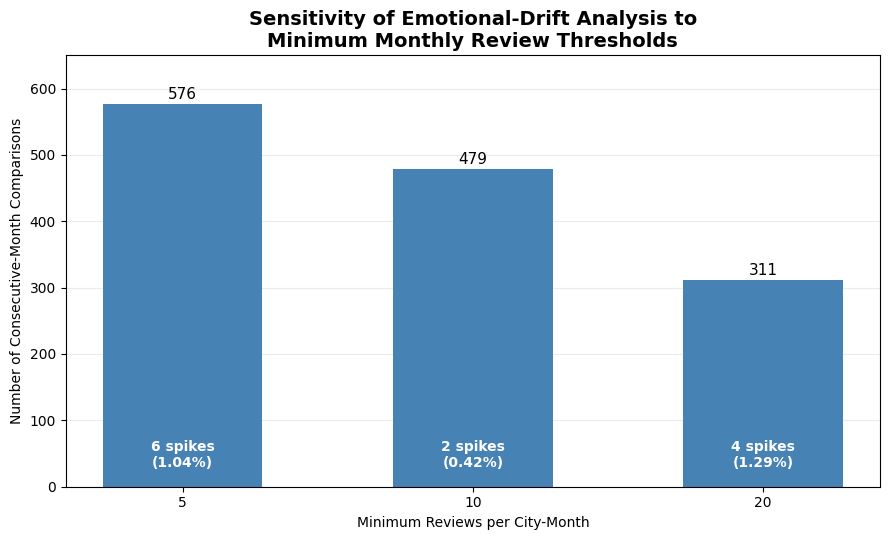

,Minimum_Reviews,Comparisons,Extreme_Spikes,Spike_Percentage
0,5,576,6,1.041667
1,10,479,2,0.417537
2,20,311,4,1.286174


In [27]:

import pandas as pd
import matplotlib.pyplot as plt

# Results from the review-threshold sensitivity analysis
robustness = pd.DataFrame({
    "Minimum_Reviews": [5, 10, 20],
    "Comparisons": [576, 479, 311],
    "Extreme_Spikes": [6, 2, 4]
})

robustness["Spike_Percentage"] = (
    robustness["Extreme_Spikes"]
    / robustness["Comparisons"] * 100
)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    robustness["Minimum_Reviews"].astype(str),
    robustness["Comparisons"],
    color="#4682B4",
    width=0.55
)

for bar, value in zip(bars, robustness["Comparisons"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 8,
        str(value),
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Sensitivity of Emotional-Drift Analysis to\n"
    "Minimum Monthly Review Thresholds",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Minimum Reviews per City-Month")
ax.set_ylabel("Number of Consecutive-Month Comparisons")
ax.set_ylim(0, 650)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Display detected extreme spikes below each bar
for i, row in robustness.iterrows():
    ax.text(
        i,
        30,
        f"{int(row['Extreme_Spikes'])} spikes\n"
        f"({row['Spike_Percentage']:.2f}%)",
        ha="center",
        fontsize=10,
        color="white",
        fontweight="bold"
    )

plt.tight_layout()

output_file = figures_dir / "Figure11_Threshold_Robustness.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

display(robustness)


### Interpretation of Figure 9

Figure 9 evaluates the sensitivity of emotional-drift detection to different minimum monthly review thresholds.

When the minimum review threshold increased from 5 to 20, the number of valid consecutive-month comparisons decreased from 576 to 311. This shows the trade-off between sample-size requirements and temporal coverage.

The number of detected extreme drift episodes varied across thresholds, with 6, 2 and 4 episodes at thresholds of 5, 10 and 20 reviews, respectively.

These differences occur because changing the threshold affects both the eligible monthly comparisons and the city-specific statistical baselines used for spike detection.

The analysis uses a minimum of 10 reviews per city-month as the primary threshold, while thresholds of 5 and 20 are used to assess sensitivity. The results should therefore be interpreted alongside the availability of review data.

## Figure 10: Bootstrap Uncertainty Analysis of Extreme Emotional-Drift Episodes

This analysis examines the uncertainty associated with the two extreme emotional-drift episodes detected in Miami and Marrakech.

Bootstrap resampling is used to estimate how much the Jensen–Shannon distance changes when different samples of reviews are selected from the same months.

For each episode, reviews are randomly sampled with replacement within each month. The average seven-dimensional emotion distributions are recalculated, and the Jensen–Shannon distance between the two months is measured.

The procedure is repeated 2,000 times to estimate a 95% bootstrap percentile confidence interval.

This analysis helps evaluate the stability of the observed emotional drift, particularly when monthly review counts are small. The confidence intervals describe sampling uncertainty and do not establish statistical significance or causation.

In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial.distance import jensenshannon

# Use the project folder defined earlier
try:
    project_dir
except NameError:
    project_dir = Path.cwd()

figures_dir = project_dir / "figures" / "final_thesis"
figures_dir.mkdir(parents=True, exist_ok=True)

# Load original review-level emotion data
reviews_file = project_dir / "Tourism_Reviews_Emotion.csv"

if not reviews_file.exists():
    raise FileNotFoundError(
        f"Cannot find {reviews_file}. Check your project folder."
    )

reviews = pd.read_csv(reviews_file)

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

required_cols = ["City", "Month_Year", "Model_Text"] + emotion_cols

missing_cols = [
    col for col in required_cols
    if col not in reviews.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# Exclude the same 7 unusable text records
reviews = reviews[
    reviews["Model_Text"].notna()
    & reviews["Model_Text"].astype(str).str.strip().ne("")
].copy()

# Convert dates
reviews["Month_Year"] = pd.to_datetime(
    reviews["Month_Year"].astype(str),
    errors="coerce"
).dt.to_period("M")

# Check valid emotion probabilities
reviews[emotion_cols] = reviews[emotion_cols].apply(
    pd.to_numeric, errors="coerce"
)

valid_scores = (
    reviews[emotion_cols].notna().all(axis=1)
    & reviews[emotion_cols].ge(0).all(axis=1)
    & reviews[emotion_cols].le(1).all(axis=1)
    & np.isclose(
        reviews[emotion_cols].sum(axis=1),
        1.0,
        atol=1e-4
    )
)

reviews = reviews.loc[valid_scores].copy()

print("Usable reviews:", len(reviews))
print("Cities:", reviews["City"].nunique())
print("Data loaded successfully.")


Usable reviews: 22085
Cities: 10
Data loaded successfully.


In [31]:

# Bootstrap analysis for two extreme drift episodes

episodes = [
    ("Miami", "2020-11", "2020-12"),
    ("Marrakech", "2024-11", "2024-12")
]

n_bootstrap = 2000
rng = np.random.default_rng(42)

bootstrap_results = []
bootstrap_distributions = {}

for city, previous_month, current_month in episodes:

    previous_data = reviews[
        (reviews["City"] == city)
        & (reviews["Month_Year"] == pd.Period(previous_month))
    ][emotion_cols].to_numpy(dtype=float)

    current_data = reviews[
        (reviews["City"] == city)
        & (reviews["Month_Year"] == pd.Period(current_month))
    ][emotion_cols].to_numpy(dtype=float)

    n_previous = len(previous_data)
    n_current = len(current_data)

    if n_previous == 0 or n_current == 0:
        raise ValueError(
            f"Missing review data for {city}: "
            f"{previous_month} or {current_month}"
        )

    # Observed JS distance
    observed_js = jensenshannon(
        previous_data.mean(axis=0),
        current_data.mean(axis=0)
    )

    bootstrap_js = np.empty(n_bootstrap)

    for b in range(n_bootstrap):

        previous_indices = rng.integers(
            0, n_previous, size=n_previous
        )

        current_indices = rng.integers(
            0, n_current, size=n_current
        )

        previous_mean = previous_data[
            previous_indices
        ].mean(axis=0)

        current_mean = current_data[
            current_indices
        ].mean(axis=0)

        bootstrap_js[b] = jensenshannon(
            previous_mean,
            current_mean
        )

    ci_lower, ci_upper = np.percentile(
        bootstrap_js, [2.5, 97.5]
    )

    bootstrap_distributions[city] = bootstrap_js

    bootstrap_results.append({
        "City": city,
        "Previous_Month": previous_month,
        "Current_Month": current_month,
        "Previous_Reviews": n_previous,
        "Current_Reviews": n_current,
        "Observed_JS": observed_js,
        "Bootstrap_Mean_JS": bootstrap_js.mean(),
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper
    })

bootstrap_summary = pd.DataFrame(bootstrap_results)

display(bootstrap_summary.round(4))




,City,Previous_Month,Current_Month,Previous_Reviews,Current_Reviews,Observed_JS,Bootstrap_Mean_JS,CI_Lower,CI_Upper
0,Miami,2020-11,2020-12,10,13,0.4237,0.4534,0.3135,0.5873
1,Marrakech,2024-11,2024-12,23,24,0.2977,0.3238,0.1980,0.4464


### Bootstrap Uncertainty Analysis

Bootstrap resampling was used to examine the uncertainty of the two extreme emotional-drift episodes detected in Miami and Marrakech.

For Miami, the observed Jensen–Shannon distance was 0.4237, with a 95% bootstrap percentile interval of 0.3135 to 0.5873. For Marrakech, the observed distance was 0.2977, with an interval of 0.1980 to 0.4464.

Miami showed a higher observed drift value, but its estimate was based on fewer reviews. Both episodes showed uncertainty, and their bootstrap intervals overlapped.

These results suggest that the detected emotional changes should be interpreted carefully, especially when monthly review counts are small. The bootstrap analysis measures estimation uncertainty but does not establish whether the changes were statistically significant.

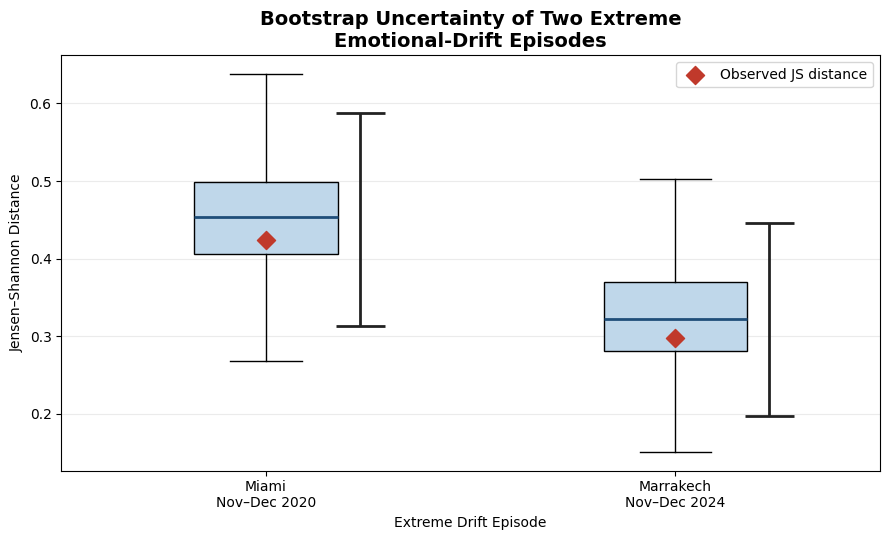

Figure saved: c:\Users\vidya\OneDrive\Documents\GitHub\sentiment-drift-analysis-tourism-reviews\figures\final_thesis\Figure12_Bootstrap_Uncertainty.png
Bootstrap results saved successfully.


In [32]:
fig, ax = plt.subplots(figsize=(9, 5.5))

cities = bootstrap_summary["City"].tolist()
positions = np.arange(len(cities))

observed = bootstrap_summary["Observed_JS"].to_numpy()
lower = bootstrap_summary["CI_Lower"].to_numpy()
upper = bootstrap_summary["CI_Upper"].to_numpy()

# Asymmetric confidence interval error bars
errors = np.vstack([
    np.maximum(observed - lower, 0),
    np.maximum(upper - observed, 0)
])

# Draw the bootstrap distributions
for i, city in enumerate(cities):
    values = bootstrap_distributions[city]

    ax.boxplot(
        values,
        positions=[i],
        widths=0.35,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#BFD7EA"},
        medianprops={"color": "#1F4E79", "linewidth": 2}
    )

# Mark observed JS distances
ax.scatter(
    positions,
    observed,
    color="#C0392B",
    s=85,
    marker="D",
    zorder=5,
    label="Observed JS distance"
)

# Show bootstrap percentile intervals
for i in range(len(cities)):
    ax.vlines(
        i + 0.23,
        lower[i],
        upper[i],
        color="#222222",
        linewidth=2
    )
    ax.hlines(
        [lower[i], upper[i]],
        i + 0.17,
        i + 0.29,
        color="#222222",
        linewidth=2
    )

ax.set_xticks(positions)
ax.set_xticklabels([
    "Miami\nNov–Dec 2020",
    "Marrakech\nNov–Dec 2024"
])

ax.set_title(
    "Bootstrap Uncertainty of Two Extreme\n"
    "Emotional-Drift Episodes",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Jensen–Shannon Distance")
ax.set_xlabel("Extreme Drift Episode")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()

output_file = figures_dir / "Figure12_Bootstrap_Uncertainty.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
bootstrap_summary.to_csv(
    project_dir / "results" / "Bootstrap_Uncertainty_Summary.csv",
    index=False
)

print("Figure saved:", output_file)
print("Bootstrap results saved successfully.")



### Interpretation of Figure 11

Figure 11 presents the bootstrap uncertainty analysis for the two extreme emotional-drift episodes identified in Miami and Marrakech.

The observed Jensen–Shannon distance was 0.424 for Miami and 0.298 for Marrakech. Bootstrap resampling was performed 2,000 times to examine the variability of these estimates.

Miami showed a higher observed emotional-drift value than Marrakech. However, both episodes showed variation across bootstrap samples, and their uncertainty distributions overlapped.

The results highlight the importance of considering sample size when interpreting emotional-drift measurements. This is particularly relevant for Miami, where only 10 and 13 reviews were available for the two comparison months.

The bootstrap analysis provides information about the uncertainty of the estimated drift but does not establish statistical significance or a causal relationship with external events.

## Statistical Validation Using a Permutation Test

After identifying extreme emotional-drift episodes and estimating their uncertainty using bootstrap resampling, a permutation test was used to evaluate the evidence for changes in monthly emotion distributions.

The analysis focuses on two episodes:

- Miami: November to December 2020
- Marrakech: November to December 2024

The test compares the observed Jensen–Shannon distance with distances obtained by randomly reassigning individual reviews between the two months while keeping the original monthly sample sizes.

The null hypothesis assumes that both months have the same underlying distribution of review-level emotion scores.

A small p-value indicates that the observed difference would be unusual under this hypothesis. It does not establish that an external event caused the change.

In [33]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.spatial.distance import jensenshannon

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

# Find the emotion dataset in the project
possible_files = [
    Path("Tourism_Reviews_Emotion.csv"),
    Path("data/Tourism_Reviews_Emotion.csv"),
    Path("results/Tourism_Reviews_Emotion.csv")
]

emotion_file = next(
    (path for path in possible_files if path.exists()),
    None
)

if emotion_file is None:
    raise FileNotFoundError(
        "Tourism_Reviews_Emotion.csv not found. "
        "Please check its location in your project."
    )

reviews = pd.read_csv(emotion_file)

# Exclude reviews with empty model input
valid_text = reviews["Model_Text"].notna() & (
    reviews["Model_Text"].fillna("").astype(str).str.strip() != ""
)
reviews = reviews.loc[valid_text].copy()

reviews["Month_Year"] = pd.to_datetime(
    reviews["Month_Year"].astype(str),
    errors="coerce"
).dt.to_period("M")

print("Reviews loaded:", len(reviews))
print("Cities:", reviews["City"].nunique())
print("Emotion columns available:",
      all(col in reviews.columns for col in emotion_cols))


Reviews loaded: 22085
Cities: 10
Emotion columns available: True


In [34]:

def permutation_test_emotion_drift(
    data, city, previous_month, current_month,
    n_permutations=10000, seed=42
):
    previous_month = pd.Period(previous_month, freq="M")
    current_month = pd.Period(current_month, freq="M")

    previous = data.loc[
        (data["City"] == city) &
        (data["Month_Year"] == previous_month),
        emotion_cols
    ].dropna().to_numpy(dtype=float)

    current = data.loc[
        (data["City"] == city) &
        (data["Month_Year"] == current_month),
        emotion_cols
    ].dropna().to_numpy(dtype=float)

    n_previous = len(previous)
    n_current = len(current)

    if n_previous == 0 or n_current == 0:
        raise ValueError(f"Missing reviews for {city}")

    def js_distance(a, b):
        return jensenshannon(
            a.mean(axis=0),
            b.mean(axis=0)
        )

    observed_js = js_distance(previous, current)

    combined = np.vstack([previous, current])
    rng = np.random.default_rng(seed)

    permuted_distances = np.empty(n_permutations)

    for i in range(n_permutations):
        indices = rng.permutation(len(combined))

        group_a = combined[indices[:n_previous]]
        group_b = combined[indices[n_previous:]]

        permuted_distances[i] = js_distance(
            group_a, group_b
        )

    # Plus-one correction
    p_value = (
        np.sum(permuted_distances >= observed_js) + 1
    ) / (n_permutations + 1)

    return {
        "City": city,
        "Previous_Month": str(previous_month),
        "Current_Month": str(current_month),
        "Previous_Reviews": n_previous,
        "Current_Reviews": n_current,
        "Observed_JS": observed_js,
        "Permutation_Mean_JS": permuted_distances.mean(),
        "P_Value": p_value
    }


episodes = [
    ("Miami", "2020-11", "2020-12"),
    ("Marrakech", "2024-11", "2024-12")
]

results = []

for city, previous_month, current_month in episodes:
    result = permutation_test_emotion_drift(
        reviews, city, previous_month, current_month
    )
    results.append(result)

permutation_results = pd.DataFrame(results)

display(permutation_results.round(4))


,City,Previous_Month,Current_Month,Previous_Reviews,Current_Reviews,Observed_JS,Permutation_Mean_JS,P_Value
0,Miami,2020-11,2020-12,10,13,0.4237,0.2542,0.0159
1,Marrakech,2024-11,2024-12,23,24,0.2977,0.1652,0.0060


In [35]:

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

output_file = results_dir / "Permutation_Test_Results.csv"

permutation_results.to_csv(output_file, index=False)

print("Permutation test results saved:", output_file)


Permutation test results saved: results\Permutation_Test_Results.csv


### Interpretation of the Permutation Test

Permutation tests were conducted to examine the emotional differences between consecutive months for two extreme drift episodes.

For Miami, the Jensen–Shannon distance between November and December 2020 was 0.4237, with a permutation p-value of 0.0159.

For Marrakech, the distance between November and December 2024 was 0.2977, with a permutation p-value of 0.0060.

Both episodes showed statistically significant differences at the conventional 5% level in these exploratory tests.

However, these results should be interpreted carefully. The Miami episode contains relatively few reviews, and both episodes were selected after examining the drift results. Therefore, the p-values do not account for the full spike-selection process or multiple comparisons.

The findings provide initial statistical evidence of changes in the emotion distributions, but they do not establish a causal relationship with external events.

## Multiple-Testing Correction

The emotional-drift analysis includes 479 consecutive-month comparisons across ten tourist destinations.

Testing many monthly comparisons increases the chance of identifying statistically significant differences by chance.

To address this issue, permutation tests are applied to all eligible monthly comparisons. The resulting p-values are adjusted using the Benjamini–Hochberg false discovery rate procedure.

This analysis helps distinguish individual exploratory findings from results that remain statistically significant after accounting for multiple comparisons.

In [37]:


%pip install statsmodels

from statsmodels.stats.multitest import multipletests

# Load the existing drift results
drift_results = pd.read_csv(
    "results/Emotional_Drift_Results.csv"
)

# Convert date columns
drift_results["Previous_Month"] = pd.to_datetime(
    drift_results["Previous_Month"]
)

drift_results["Month_Year"] = pd.to_datetime(
    drift_results["Month_Year"]
)

# Use the primary consecutive-month comparisons
drift_results = drift_results[
    drift_results["Month_Gap"] == 1
].copy()

print("Comparisons to test:", len(drift_results))

all_results = []

for _, row in drift_results.iterrows():
    result = permutation_test_emotion_drift(
        reviews,
        row["City"],
        row["Previous_Month"].strftime("%Y-%m"),
        row["Month_Year"].strftime("%Y-%m"),
        n_permutations=2000,
        seed=42
    )
    all_results.append(result)

all_tests = pd.DataFrame(all_results)

# Apply Benjamini-Hochberg FDR correction
rejected, adjusted_p, _, _ = multipletests(
    all_tests["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

all_tests["FDR_Adjusted_P"] = adjusted_p
all_tests["Significant_After_FDR"] = rejected

print("Total tests:", len(all_tests))
print(
    "Significant before correction:",
    (all_tests["P_Value"] < 0.05).sum()
)
print(
    "Significant after FDR correction:",
    all_tests["Significant_After_FDR"].sum()
)

display(
    all_tests.sort_values("P_Value").head(15).round(4)
)

# Save results
all_tests.to_csv(
    "results/Permutation_Tests_All_Months.csv",
    index=False
)


   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.1/11.3 MB 2.8 MB/s eta 0:00:04
   - -------------------------------------- 0.3/11.3 MB 3.2 MB/s eta 0:00:04
   - -------------------------------------- 0.5/11.3 MB 3.1 MB/s eta 0:00:04
   -- ------------------------------------- 0.7/11.3 MB 3.4 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/11.3 MB 3.2 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.3 MB 3.2 MB/s eta 0:00:04
   ---- ----------------------------------- 1.2/11.3 MB 3.1 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/11.3 MB 3.1 MB/s eta 0:00:04
   ----- ---------------------------------- 1.5/11.3 MB 3.0 MB/s eta 0:00:04
   ------ --------------------------------- 1.7/11.3 MB 3.1 MB/s eta 0:00:04
   ------ --------------------------------- 1.9/11.3 MB 3.2 MB/s eta 0:00:03
   ------- -------------------------------- 2.0/11.3 MB 3.0 MB/s eta 0:00:04
   ---


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Comparisons to test: 479
Total tests: 479
Significant before correction: 41
Significant after FDR correction: 0


,City,Previous_Month,Current_Month,Previous_Reviews,Current_Reviews,Observed_JS,Permutation_Mean_JS,P_Value,FDR_Adjusted_P,Significant_After_FDR
99,Barcelona,2022-04,2022-05,103,130,0.1541,0.0658,0.0005,0.1197,False
10,Agra,2020-01,2020-02,13,123,0.2936,0.1399,0.0005,0.1197,False
211,Dubai,2022-12,2023-01,46,58,0.1982,0.0888,0.0015,0.2394,False
57,Bali,2022-11,2022-12,20,68,0.3039,0.1498,0.0020,0.2394,False
50,Bali,2022-04,2022-05,19,31,0.2842,0.1344,0.0030,0.2611,False
418,Rio de Janeiro,2023-07,2023-08,24,50,0.2360,0.1258,0.0040,0.2611,False
81,Barcelona,2019-03,2019-04,51,50,0.1879,0.1041,0.0050,0.2611,False
176,Dubai,2019-05,2019-06,77,133,0.1242,0.0614,0.0050,0.2611,False
154,Cairo,2023-03,2023-04,20,21,0.2873,0.1517,0.0055,0.2611,False
278,Marrakech,2024-11,2024-12,23,24,0.2977,0.1643,0.0055,0.2611,False


### Interpretation of Multiple-Testing Results

Permutation tests were conducted across 479 consecutive-month comparisons to assess changes in emotion distributions across ten tourist destinations between 2019 and 2024.

Several comparisons produced small unadjusted p-values. However, after applying the Benjamini–Hochberg false discovery rate correction, no comparison met the 5% significance threshold.

This suggests that although emotional changes were observed across destinations, the evidence was not strong enough to establish statistically significant differences after accounting for multiple testing.

The extreme drift episodes identified in Miami and Marrakech remain useful for exploratory analysis. However, they should not be interpreted as statistically confirmed changes or as evidence of causal relationships with external events.

These findings highlight the importance of review volume, statistical uncertainty, and multiple-testing correction when studying emotional drift in online tourism reviews.

In [43]:

print("Total comparisons:", len(all_tests))

print(
    "Significant before FDR:",
    (all_tests["P_Value"] < 0.05).sum()
)

print(
    "Significant after FDR:",
    all_tests["Significant_After_FDR"].sum()
)

print(
    "Minimum adjusted p-value:",
    all_tests["FDR_Adjusted_P"].min()
)

# Check the two main case studies
case_studies = all_tests[
    (
        (all_tests["City"] == "Miami") &
        (all_tests["Current_Month"] == "2020-12")
    ) |
    (
        (all_tests["City"] == "Marrakech") &
        (all_tests["Current_Month"] == "2024-12")
    )
]

display(case_studies)


Total comparisons: 479
Significant before FDR: 41
Significant after FDR: 0
Minimum adjusted p-value: 0.11969015492253873


,City,Previous_Month,Current_Month,Previous_Reviews,Current_Reviews,Observed_JS,Permutation_Mean_JS,P_Value,FDR_Adjusted_P,Significant_After_FDR
278,Marrakech,2024-11,2024-12,23,24,0.297725,0.164268,0.005497,0.261142,False
295,Miami,2020-11,2020-12,10,13,0.423731,0.253279,0.014493,0.408355,False


### Statistical Validation of the Two Extreme Drift Episodes

Two extreme emotional-drift episodes were examined using permutation tests and false discovery rate correction.

For Miami, the Jensen–Shannon distance between November and December 2020 was 0.4237. The unadjusted permutation p-value was 0.0145, while the FDR-adjusted p-value was 0.4084.

For Marrakech, the Jensen–Shannon distance between November and December 2024 was 0.2977. The unadjusted p-value was 0.0055, while the FDR-adjusted p-value was 0.2611.

Although both episodes showed significant differences in the exploratory permutation tests, neither remained statistically significant after correcting for multiple comparisons.

These results indicate that large observed emotional changes do not necessarily provide strong statistical evidence after accounting for uncertainty and the number of comparisons performed.

Both episodes are therefore retained as exploratory case studies rather than statistically confirmed emotional shifts.

## Temporal Context of Extreme Emotional-Drift Episodes

This section examines the monthly emotion patterns surrounding the two extreme drift episodes identified in Miami and Marrakech.

The objective is to understand whether the detected changes were isolated fluctuations or part of broader emotional trends.

For Miami, the analysis examines the months surrounding December 2020. For Marrakech, it examines the months leading up to December 2024.

Monthly review counts are considered when interpreting the results because months with fewer reviews may produce less stable emotion estimates.

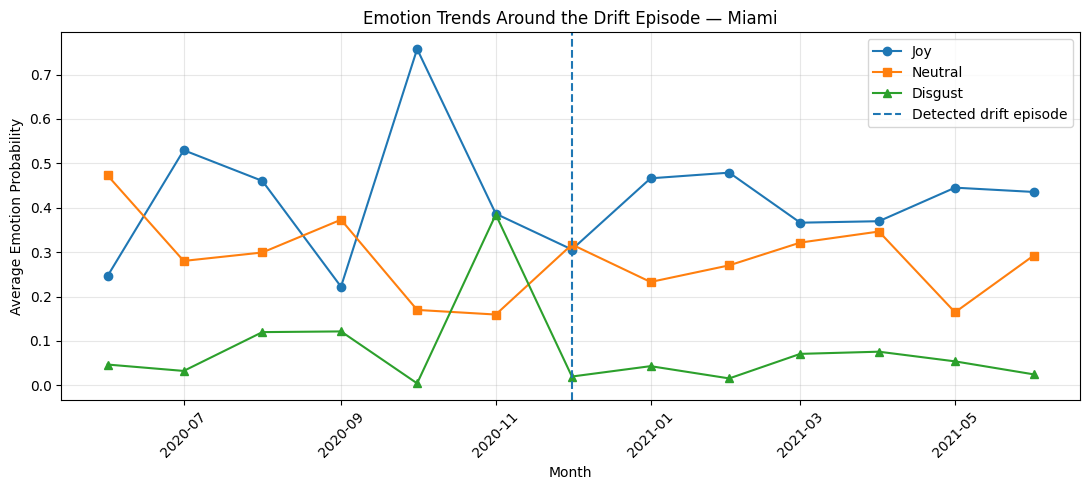

,Month_Year,Review_Count,Joy,Neutral,Disgust
423,2020-06-01,12,0.246,0.473,0.047
424,2020-07-01,10,0.530,0.280,0.033
425,2020-08-01,4,0.460,0.299,0.120
426,2020-09-01,11,0.222,0.373,0.122
427,2020-10-01,5,0.757,0.170,0.005
428,2020-11-01,10,0.386,0.160,0.385
429,2020-12-01,13,0.306,0.317,0.020
430,2021-01-01,22,0.466,0.233,0.043
431,2021-02-01,34,0.479,0.270,0.016
432,2021-03-01,40,0.366,0.322,0.071


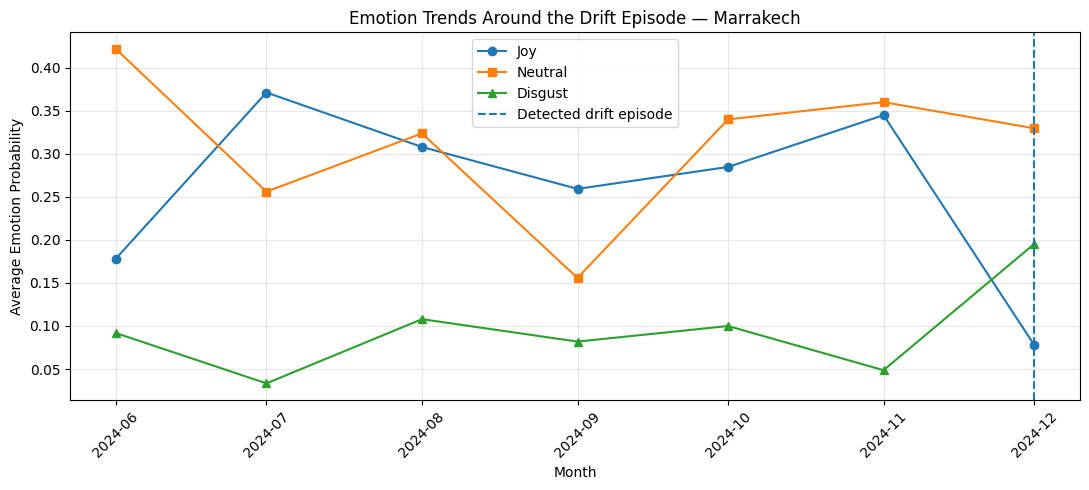

,Month_Year,Review_Count,Joy,Neutral,Disgust
399,2024-06-01,36,0.178,0.422,0.092
400,2024-07-01,27,0.371,0.256,0.033
401,2024-08-01,40,0.308,0.324,0.108
402,2024-09-01,22,0.259,0.156,0.082
403,2024-10-01,52,0.285,0.340,0.100
404,2024-11-01,23,0.345,0.360,0.049
405,2024-12-01,24,0.078,0.330,0.195


In [44]:

import pandas as pd
import matplotlib.pyplot as plt

# Load existing monthly emotion profiles
monthly_context = pd.read_csv(
    "results/Monthly_Emotion_Profiles.csv"
)

monthly_context["Month_Year"] = pd.to_datetime(
    monthly_context["Month_Year"]
)

episodes = [
    ("Miami", "2020-12-01"),
    ("Marrakech", "2024-12-01")
]

for city, episode_date in episodes:

    episode_date = pd.Timestamp(episode_date)

    # Six months before and after, where available
    start = episode_date - pd.DateOffset(months=6)
    end = episode_date + pd.DateOffset(months=6)

    city_data = monthly_context[
        (monthly_context["City"] == city) &
        (monthly_context["Month_Year"] >= start) &
        (monthly_context["Month_Year"] <= end)
    ].sort_values("Month_Year")

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(
        city_data["Month_Year"],
        city_data["Joy"],
        marker="o",
        label="Joy"
    )

    ax.plot(
        city_data["Month_Year"],
        city_data["Neutral"],
        marker="s",
        label="Neutral"
    )

    ax.plot(
        city_data["Month_Year"],
        city_data["Disgust"],
        marker="^",
        label="Disgust"
    )

    ax.axvline(
        episode_date,
        linestyle="--",
        label="Detected drift episode"
    )

    ax.set_title(
        f"Emotion Trends Around the Drift Episode — {city}"
    )
    ax.set_xlabel("Month")
    ax.set_ylabel("Average Emotion Probability")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    display(
        city_data[
            ["Month_Year", "Review_Count",
             "Joy", "Neutral", "Disgust"]
        ].round(3)
    )


### Temporal Analysis of the Miami Drift Episode

The Miami results show noticeable changes in predicted emotions between November and December 2020.

The most prominent change was a decrease in Disgust, accompanied by an increase in Neutral and a smaller decrease in Joy.

The surrounding months suggest that the high Disgust value in November 2020 may have been a temporary fluctuation rather than the beginning of a long-term emotional trend.

However, the two months contained only 10 and 13 reviews, respectively. Therefore, the estimated emotion distributions may be sensitive to individual reviews.

Although the episode was identified as an extreme drift event using Jensen–Shannon distance and robust-Z scores, it did not remain statistically significant after multiple-testing correction.

The episode is therefore interpreted as an exploratory finding rather than a confirmed persistent emotional shift.

### Temporal Analysis of the Marrakech Drift Episode

The Marrakech results show a noticeable change in predicted emotions between November and December 2024.

Joy decreased from approximately 0.345 to 0.078, while Disgust increased from approximately 0.049 to 0.196. Neutral showed only a small decrease.

During the preceding months, Joy and Disgust fluctuated, but December showed the lowest Joy and highest Disgust values within the displayed period.

The Jensen–Shannon distance for this transition was 0.2977. The comparison included 23 reviews in November and 24 in December.

Although the original permutation test suggested a significant difference, the result was not statistically significant after false discovery rate correction (adjusted p-value = 0.2611).

Furthermore, because the dataset ends in December 2024, it is not possible to determine whether the observed change continued into subsequent months.

The Marrakech episode is therefore treated as an exploratory case study that illustrates how monthly emotion distributions can change over time.